# Options Lab: precificação de opções europeias e hedge discreto

O preço de uma opção pode ser obtido por uma fórmula analítica, por uma árvore
de estados ou pela média de pagamentos simulados. A concordância entre esses
métodos depende de hipóteses comuns sobre o ativo e sobre o financiamento da
carteira. Mesmo quando os preços concordam, uma estratégia de replicação
executada em datas discretas apresenta ganhos e perdas residuais.

Este estudo compara Black–Scholes, a árvore de Cox–Ross–Rubinstein (CRR) e
Monte Carlo para opções europeias. O delta de Black–Scholes é usado em uma
carteira autofinanciada, cuja contabilidade permite medir o efeito da frequência
de negociação, dos custos proporcionais e de uma especificação incorreta da
volatilidade. Os experimentos utilizam dados simulados e não incluem calibração
a preços de mercado.

Os cálculos são implementados no pacote `options_lab`. O notebook pode ser
executado integralmente, a partir da raiz do repositório ou da pasta `notebooks`,
após a instalação com `python -m pip install -e ".[notebook]"`. A execução
recalcula as amostras e grava as figuras e os relatórios em `reports/`.

In [1]:
import io
import json
import math
import platform
import random
import runpy
import statistics
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from options_lab import (
    european_payoff, black_scholes_price, black_scholes_greeks,
    binomial_crr_price, monte_carlo_price, simulate_gbm_path,
    delta_hedge_path, run_hedging_experiments,
)

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'src/options_lab').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Execute na raiz do repositório ou na pasta notebooks.')
REPORTS = ROOT / 'reports'
REPORTS.mkdir(exist_ok=True)
plotters = {name: runpy.run_path(str(ROOT / 'scripts' / f'plot_{name}.py'))
            for name in ['greeks', 'crr_tree', 'crr_convergence', 'monte_carlo',
                         'delta_hedge', 'hedging_experiments']}

def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines.extend('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown('\n'.join(lines)))

def figure(fig, filename):
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=160, facecolor='white')
    content = buffer.getvalue()
    (REPORTS / filename).write_bytes(content)
    display(Image(data=content))
    plt.close(fig)

def save_report(data, filename):
    (REPORTS / filename).write_text(
        json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False) + '\n',
        encoding='utf-8',
    )

parameters = dict(spot=100.0, strike=100.0, time_to_maturity=1.0,
                  rate=0.05, volatility=0.20)
S, K, tau, r, sigma = (parameters[name] for name in
                      ['spot', 'strike', 'time_to_maturity', 'rate', 'volatility'])
print(f'Python {platform.python_version()} | options-lab {version("options-lab")}')

Python 3.12.14 | options-lab 1.0.0


## Contratos, unidades e hipóteses

Uma call europeia confere ao comprador o direito de adquirir o ativo por um
preço de exercício $K$ na data de vencimento $T$. Uma put confere o direito de
vendê-lo pelo mesmo preço. Adota-se liquidação financeira: o vendedor paga ao
comprador o valor correspondente ao exercício, sem entrega física do ativo.
Os pagamentos, ou *payoffs*, são

$$h_C(S_T)=\max(S_T-K,0),\qquad h_P(S_T)=\max(K-S_T,0).$$

O payoff não inclui o prêmio pago na contratação. Para uma opção comprada por
$p_0$, o resultado financeiro no vencimento, considerando o financiamento
desse prêmio à taxa contínua $r$, é $h(S_T)-p_0e^{rT}$.

| Variável | Significado | Convenção |
|---|---|---|
| $S_t$ | Preço do ativo na data $t$ | Unidade monetária por unidade do ativo |
| $K$ | Preço de exercício | Mesma unidade de $S_t$ |
| $\tau=T-t$ | Prazo restante | Anos |
| $r$ | Taxa de juros | Composição contínua, em decimal |
| $\sigma$ | Volatilidade | Anualizada, em decimal |
| $C$, $P$ | Preços da call e da put | Valor de uma opção sobre uma unidade do ativo |

O caso de referência tem $S_0=K=100$, $T=1$, $r=0{,}05$ e $\sigma=0{,}20$.
Uma taxa contínua de 5% corresponde a um crescimento anual de
$e^{0{,}05}-1\approx5{,}127\%$. A volatilidade de 20% determina um desvio padrão
$0{,}20\sqrt{\Delta t}$ para o log-retorno em um intervalo de duração $\Delta t$.

O modelo admite ausência de dividendos, juros e volatilidade constantes,
posições fracionárias e empréstimos à mesma taxa das aplicações. Custos de
negociação são nulos na precificação de referência e aparecem explicitamente
nos experimentos de hedge. Cada contrato tem multiplicador igual a um.

In [2]:
table(['Preço no vencimento', 'Payoff da call', 'Payoff da put'],
      [(s, european_payoff(s, K, 'call'), european_payoff(s, K, 'put'))
       for s in [80, 100, 120]])

| Preço no vencimento | Payoff da call | Payoff da put |
| --- | --- | --- |
| 80 | 0.0 | 20.0 |
| 100 | 0.0 | 0.0 |
| 120 | 20.0 | 0.0 |

## Modelo e preço de Black–Scholes

Sob a medida neutra ao risco $\mathbb Q$, o ativo segue

$$dS_t=rS_t\,dt+\sigma S_t\,dW_t^{\mathbb Q},\qquad S_0>0.$$

O processo $W^{\mathbb Q}$ é um movimento browniano padrão, e $\mathcal F_t$
representa a informação disponível até $t$. Na avaliação de preços, escreve-se
$S=S_t$. Para $\tau>0$, o incremento normalizado
$Z=(W_T^{\mathbb Q}-W_t^{\mathbb Q})/\sqrt\tau$ é normal padrão e independente
de $\mathcal F_t$.

Essa medida define as probabilidades de precificação. Ela não representa,
necessariamente, a distribuição estatística dos retornos observados no mercado.
A conta livre de risco evolui como $B_t=e^{rt}$, e o ativo descontado
$e^{-rt}S_t$ é um martingal sob $\mathbb Q$.

Para $\tau=T-t$, a distribuição condicional do preço terminal é

$$S_T=S_t\exp\!\left[\left(r-\frac{\sigma^2}{2}\right)\tau
                +\sigma\sqrt\tau\,Z\right],\qquad Z\sim N(0,1).$$

Nas hipóteses do modelo, o preço de uma opção europeia é o valor presente da
esperança do pagamento sob $\mathbb Q$:

$$V(t,S_t)=e^{-r\tau}\mathbb E^{\mathbb Q}[h(S_T)\mid\mathcal F_t].$$

Para prazo e volatilidade positivos, o evento $S_T>K$ equivale a $Z>-d_2$, onde

$$d_1=\frac{\log(S/K)+(r+\sigma^2/2)\tau}{\sigma\sqrt\tau},
\qquad d_2=d_1-\sigma\sqrt\tau.$$

Decompondo o pagamento,

$$C=e^{-r\tau}\left(\mathbb E^{\mathbb Q}[S_T\mathbf1_{\{S_T>K\}}\mid\mathcal F_t]
                     -K\mathbb Q(S_T>K\mid\mathcal F_t)\right).$$

A identidade normal truncada
$\mathbb E[e^{aZ}\mathbf1_{\{Z>b\}}]=e^{a^2/2}\Phi(a-b)$ fornece

$$C=S\Phi(d_1)-Ke^{-r\tau}\Phi(d_2),$$
$$P=Ke^{-r\tau}\Phi(-d_2)-S\Phi(-d_1),$$

com $\Phi$ a função de distribuição da normal padrão. A paridade put–call é
$C-P=S-Ke^{-r\tau}$: as duas carteiras correspondentes têm o mesmo pagamento
terminal e, por ausência de arbitragem, o mesmo custo inicial.

In [3]:
call = black_scholes_price(**parameters)
put = black_scholes_price(**parameters, option_type='put')
discounted_strike = K * math.exp(-r * tau)
parity_gap = call - put - (S - discounted_strike)
assert math.isclose(parity_gap, 0, abs_tol=1e-12)
assert max(S-discounted_strike, 0) <= call <= S
assert max(discounted_strike-S, 0) <= put <= discounted_strike
table(['Quantidade', 'Valor'], [
    ('Call', f'{call:.10f}'), ('Put', f'{put:.10f}'),
    ('Resíduo da paridade', f'{parity_gap:.3e}'),
    ('Payoff da call com S_T=120', '20'),
    ('Resultado da compra com S_T=120', f'{20-call*math.exp(r*tau):.6f}'),
])

| Quantidade | Valor |
| --- | --- |
| Call | 10.4505835722 |
| Put | 5.5735260223 |
| Resíduo da paridade | -7.105e-15 |
| Payoff da call com S_T=120 | 20 |
| Resultado da compra com S_T=120 | 9.013604 |

O preço de referência da call é aproximadamente 10,4506. Esse número é o custo
da replicação ideal sob as hipóteses adotadas. Ele não constitui uma previsão
de lucro para o comprador nem uma recomendação de preço independente do modelo.

No vencimento, o preço coincide com o payoff. Com volatilidade zero, o ativo
evolui de forma determinística e os preços reduzem-se a
$C=\max(S-Ke^{-r\tau},0)$ e $P=\max(Ke^{-r\tau}-S,0)$. Essas fronteiras recebem
tratamento próprio na implementação.

In [4]:
table(['Caso', 'Call', 'Put'], [
    ('Vencimento, S=120',
     black_scholes_price(120, K, 0, r, sigma, 'call'),
     black_scholes_price(120, K, 0, r, sigma, 'put')),
    ('Volatilidade zero',
     f'{black_scholes_price(S,K,tau,r,0,"call"):.6f}',
     f'{black_scholes_price(S,K,tau,r,0,"put"):.6f}'),
])

| Caso | Call | Put |
| --- | --- | --- |
| Vencimento, S=120 | 20.0 | 0.0 |
| Volatilidade zero | 4.877058 | 0.000000 |

## Sensibilidades e aproximações locais

As derivadas do preço quantificam sua reação a mudanças nos parâmetros. Delta
mede a sensibilidade ao preço do ativo, gamma mede a variação do próprio delta
e vega mede a sensibilidade à volatilidade:

$$\Delta=\frac{\partial V}{\partial S},\qquad
\Gamma=\frac{\partial^2 V}{\partial S^2},\qquad
\nu=\frac{\partial V}{\partial\sigma}.$$

Para a call, $\Delta_C=\Phi(d_1)$; para a put,
$\Delta_P=\Phi(d_1)-1$. As duas opções têm

$$\Gamma=\frac{\phi(d_1)}{S\sigma\sqrt\tau},\qquad
\nu=S\phi(d_1)\sqrt\tau,$$

com $\phi$ a densidade normal padrão. Mantendo os demais parâmetros fixos, a
expansão de Taylor em relação ao ativo dá

$$V(S+\varepsilon)-V(S)
  =\Delta\varepsilon+\frac12\Gamma\varepsilon^2+o(\varepsilon^2).$$

Vega usa volatilidade em escala decimal. A passagem de 20% para 21% tem
$\Delta\sigma=0{,}01$, de modo que a aproximação da mudança de preço é
$0{,}01\nu$. As fórmulas de sensibilidades são avaliadas para prazo e
volatilidade estritamente positivos.

In [5]:
greeks = black_scholes_greeks(**parameters)
put_greeks = black_scholes_greeks(**parameters, option_type='put')
table(['Sensibilidade', 'Call', 'Put'],
      [(name, f'{getattr(greeks,name):.9f}', f'{getattr(put_greeks,name):.9f}')
       for name in ['delta', 'gamma', 'vega']])
movement = black_scholes_price(**{**parameters, 'spot': 101}) - call
table(['Variação para S: 100 → 101', 'Valor'], [
    ('Reprecificação', f'{movement:.9f}'),
    ('Delta', f'{greeks.delta:.9f}'),
    ('Delta + gamma/2', f'{greeks.delta + greeks.gamma/2:.9f}'),
])

| Sensibilidade | Call | Put |
| --- | --- | --- |
| delta | 0.636830651 | -0.363169349 |
| gamma | 0.018762017 | 0.018762017 |
| vega | 37.524034692 | 37.524034692 |

| Variação para S: 100 → 101 | Valor |
| --- | --- |
| Reprecificação | 0.646124555 |
| Delta | 0.636830651 |
| Delta + gamma/2 | 0.646211660 |

| Derivada | Diferença finita central | Erro absoluto |
| --- | --- | --- |
| delta | 0.636830643 | 8.598e-09 |
| gamma | 0.018762017 | 5.495e-11 |
| vega | 37.524034387 | 3.045e-07 |

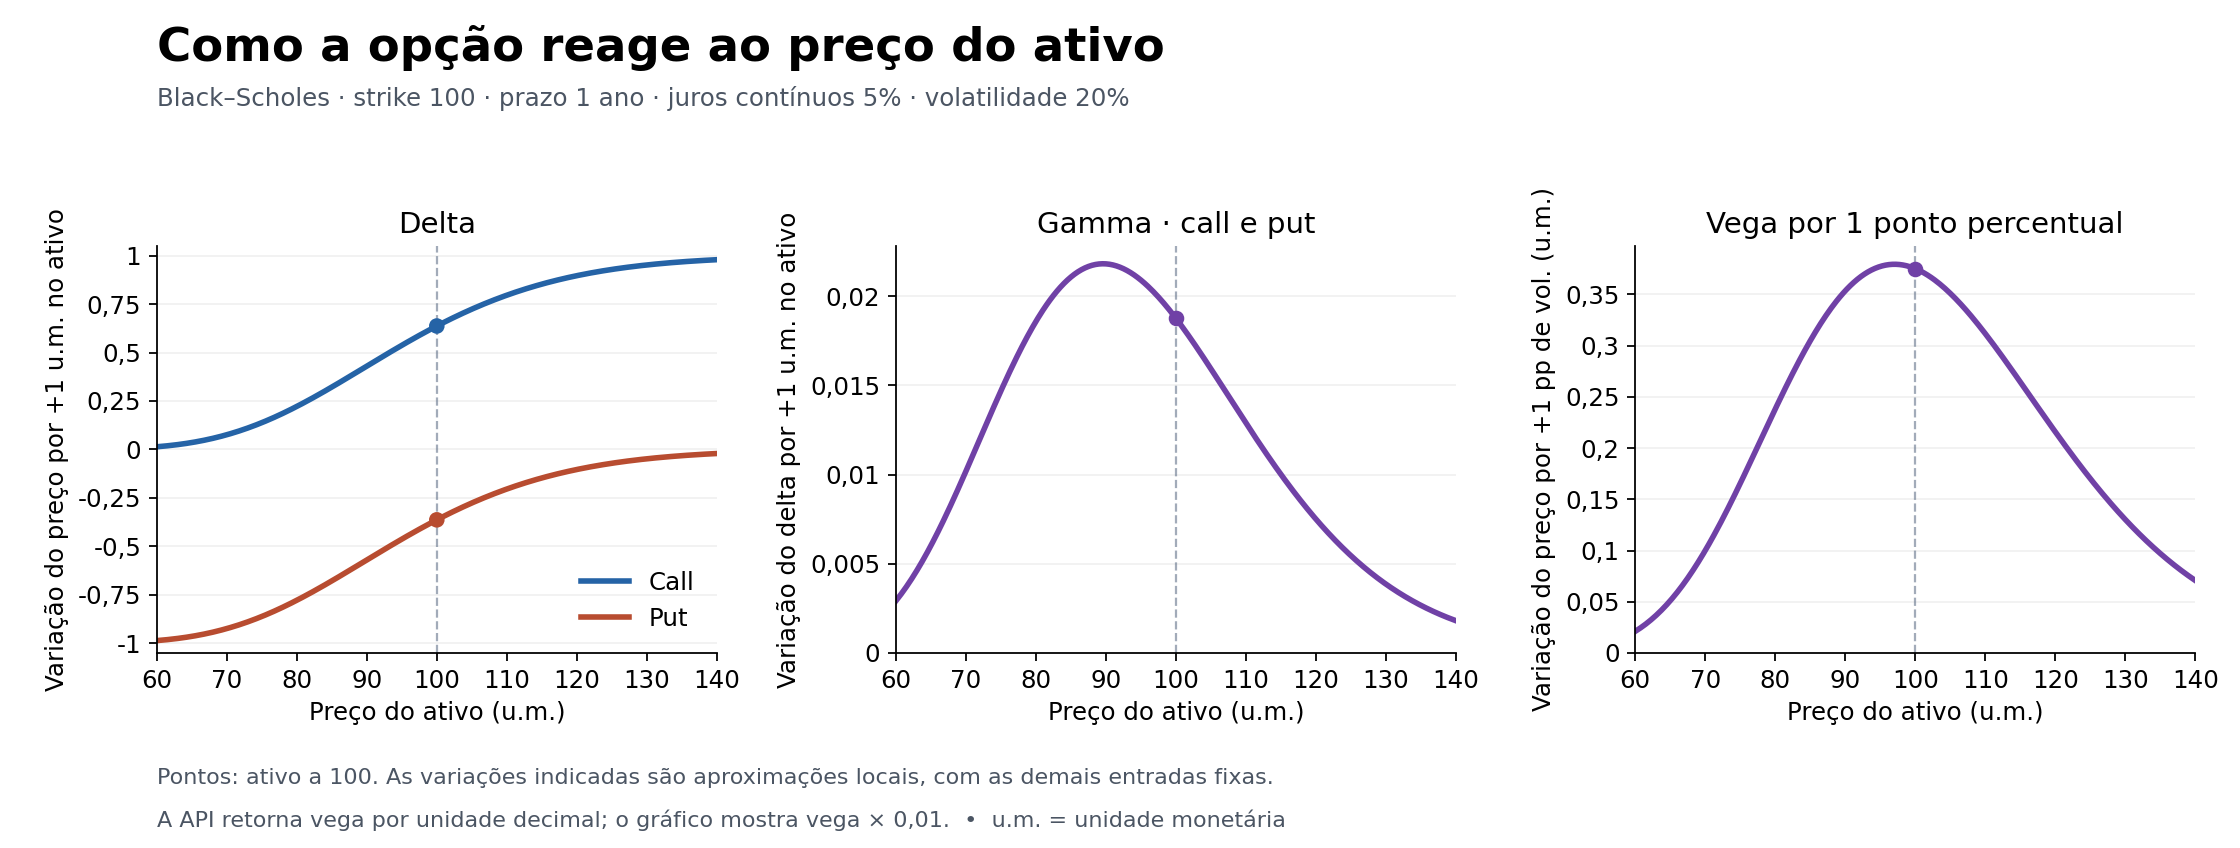

In [6]:
h, epsilon = 0.01, 0.0001
up = black_scholes_price(**{**parameters, 'spot': S+h})
down = black_scholes_price(**{**parameters, 'spot': S-h})
vol_up = black_scholes_price(**{**parameters, 'volatility': sigma+epsilon})
vol_down = black_scholes_price(**{**parameters, 'volatility': sigma-epsilon})
numerical = {'delta': (up-down)/(2*h), 'gamma': (up-2*call+down)/h**2,
             'vega': (vol_up-vol_down)/(2*epsilon)}
tolerances = {'delta': 1e-7, 'gamma': 1e-8, 'vega': 1e-6}
rows = []
for name, approximation in numerical.items():
    error = abs(approximation-getattr(greeks,name))
    assert error < tolerances[name]
    rows.append((name, f'{approximation:.9f}', f'{error:.3e}'))
table(['Derivada', 'Diferença finita central', 'Erro absoluto'], rows)
figure(plotters['greeks']['create_figure'](), 'greeks.png')

O delta da call aproxima-se de zero quando o ativo está muito abaixo do strike
e de um quando está muito acima. Gamma e vega concentram sua sensibilidade
na região próxima ao exercício, com a posição do máximo dependente dos
parâmetros. Os gráficos variam somente o preço do ativo; prazo, juros e
volatilidade permanecem fixos.

## Árvore binomial e carteira replicante

A árvore CRR divide o prazo em $N$ intervalos de tamanho $\Delta t=\tau/N$.
Em cada intervalo, o preço é multiplicado por

$$u=e^{\sigma\sqrt{\Delta t}},\qquad d=u^{-1}.$$

Uma alta seguida de uma baixa leva ao mesmo preço que uma baixa seguida de
uma alta; por isso, a árvore é recombinante. O peso neutro ao risco da alta é

$$p=\frac{e^{r\Delta t}-d}{u-d}.$$

A condição $d<e^{r\Delta t}<u$ garante $0<p<1$. Ela expressa ausência de
arbitragem na árvore e pode exigir uma grade mais fina para certos parâmetros.
O peso $p$ é determinado pela precificação; não é uma frequência de alta
estimada a partir de dados históricos.

Se a opção vale $V_u$ e $V_d$ nos dois estados seguintes, a carteira com
$\delta$ ações e caixa $A$ reproduz esses valores quando

$$\delta Su+Ae^{r\Delta t}=V_u,\qquad
  \delta Sd+Ae^{r\Delta t}=V_d.$$

A solução é

$$\delta=\frac{V_u-V_d}{S(u-d)},\qquad
A=e^{-r\Delta t}(V_d-\delta Sd).$$

O custo da carteira e o valor da opção são, portanto,

$$V=\delta S+A=e^{-r\Delta t}[pV_u+(1-p)V_d].$$

Essa igualdade decorre da replicação dos pagamentos nos dois estados. Ela é
aplicada por indução retroativa, a partir dos payoffs no vencimento. Não há
decisão de exercício antecipado, pois os contratos considerados são europeus.

| Árvore de um intervalo | Valor |
| --- | --- |
| Preço do ativo após alta / baixa | 122.140276 / 81.873075 |
| Payoffs após alta / baixa | 22.140276 / 0.000000 |
| Ações da carteira | 0.549834 |
| Caixa inicial | -42.821115 |
| Custo da replicação | 12.162285 |

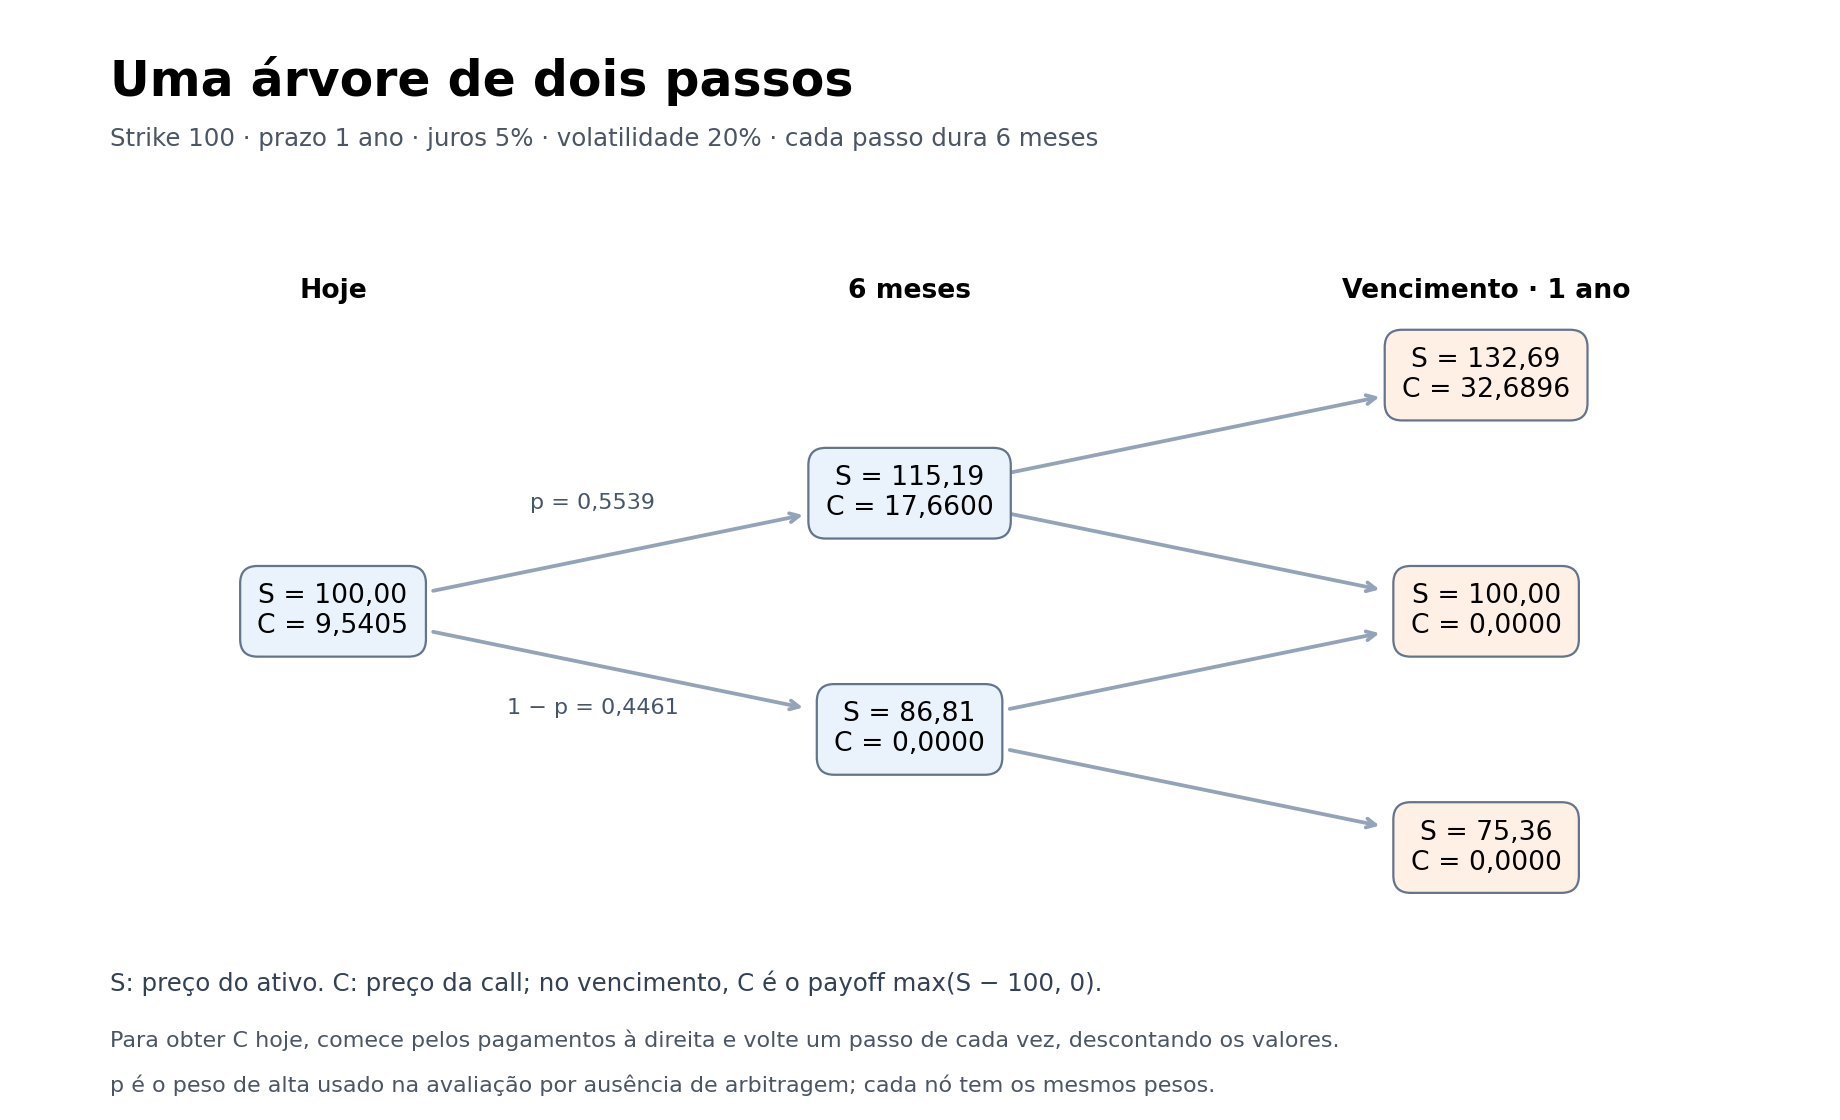

In [7]:
dt = tau
u, d = math.exp(sigma*math.sqrt(dt)), math.exp(-sigma*math.sqrt(dt))
payoff_up, payoff_down = european_payoff(S*u,K), european_payoff(S*d,K)
shares = (payoff_up-payoff_down)/(S*(u-d))
cash = math.exp(-r*dt)*(payoff_down-shares*S*d)
replica = shares*S + cash
assert math.isclose(replica, binomial_crr_price(**parameters,steps=1), abs_tol=1e-11)
table(['Árvore de um intervalo', 'Valor'], [
    ('Preço do ativo após alta / baixa', f'{S*u:.6f} / {S*d:.6f}'),
    ('Payoffs após alta / baixa', f'{payoff_up:.6f} / {payoff_down:.6f}'),
    ('Ações da carteira', f'{shares:.6f}'), ('Caixa inicial', f'{cash:.6f}'),
    ('Custo da replicação', f'{replica:.6f}'),
])
figure(plotters['crr_tree']['create_figure'](), 'crr_tree.png')

A figura representa uma árvore de dois intervalos; o cálculo anterior utiliza
apenas um, para tornar explícita a solução do sistema de replicação.
A discretização altera o preço em relação a Black–Scholes. A convergência pode
oscilar com $N$, dependendo da posição do strike em relação aos nós terminais.

| Intervalos | Call CRR | Put CRR | Erro absoluto da call |
| --- | --- | --- | --- |
| 1 | 12.16228496 | 7.28522741 | 1.71170139 |
| 2 | 9.54050134 | 4.66344379 | 0.91008223 |
| 3 | 11.04387109 | 6.16681354 | 0.59328752 |
| 10 | 10.25340904 | 5.37635149 | 0.19717453 |
| 50 | 10.41069154 | 5.53363399 | 0.03989203 |
| 100 | 10.43061166 | 5.55355411 | 0.01997191 |
| 500 | 10.44658514 | 5.56952759 | 0.00399844 |
| 1000 | 10.44858410 | 5.57152655 | 0.00199947 |

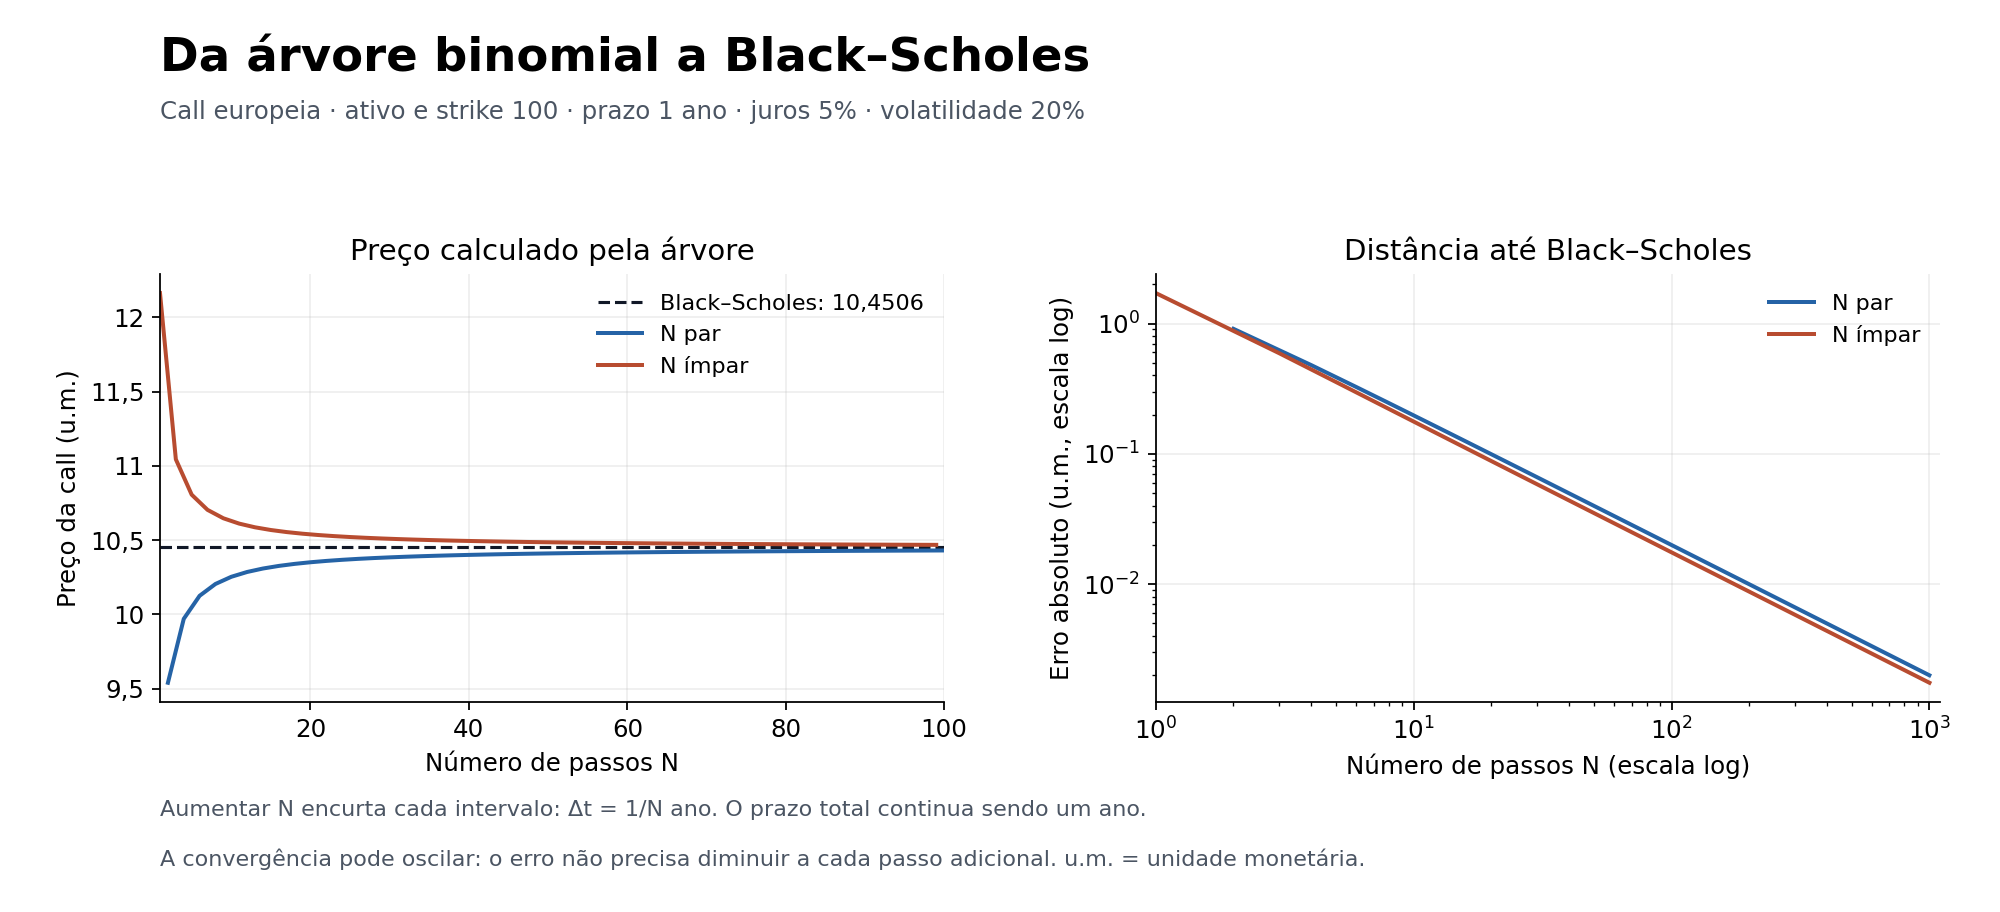

In [8]:
rows = []
for n in [1,2,3,10,50,100,500,1000]:
    c = binomial_crr_price(**parameters, steps=n)
    p = binomial_crr_price(**parameters, steps=n, option_type='put')
    assert math.isclose(c-p, S-discounted_strike, abs_tol=1e-10)
    rows.append((n, f'{c:.8f}', f'{p:.8f}', f'{abs(c-call):.8f}'))
table(['Intervalos', 'Call CRR', 'Put CRR', 'Erro absoluto da call'], rows)
figure(plotters['crr_convergence']['create_figure'](), 'crr_convergence.png')

## Precificação por Monte Carlo

Monte Carlo aproxima a esperança do pagamento descontado por uma média
amostral. Para amostras independentes $Z_j\sim N(0,1)$, definem-se

$$S_T^{(j)}=S_0e^{(r-\sigma^2/2)T+\sigma\sqrt T Z_j},\qquad
Y_j=e^{-rT}h(S_T^{(j)}),\qquad
\widehat V_M=\frac1M\sum_{j=1}^M Y_j.$$

Cada observação recebe peso $1/M$ porque os sorteios já seguem a distribuição
do modelo. Regiões mais prováveis aparecem com maior frequência; não há uma
enumeração uniforme dos possíveis preços do ativo. Para uma opção europeia
sem dependência de trajetória, basta sortear o preço terminal.

O desvio padrão amostral $s_Y$ descreve a dispersão dos pagamentos descontados.
O erro padrão da média estimada é $s_Y/\sqrt M$. O intervalo normal aproximado
de 95% é

$$\widehat V_M\pm1{,}959964\frac{s_Y}{\sqrt M}.$$

A cobertura de 95% refere-se a repetições do procedimento. Ela não garante que
um intervalo particular contenha o preço analítico. O erro amostral típico decresce
na escala $M^{-1/2}$, enquanto o erro observado em uma execução pode aumentar
ao acrescentar amostras.

In [9]:
generator = random.Random(2026)
discounted_payoffs, rows = [], []
for j in range(1,9):
    z = generator.gauss(0,1)
    terminal = S*math.exp((r-sigma*sigma/2)*tau + sigma*math.sqrt(tau)*z)
    payment = european_payoff(terminal,K)
    present = math.exp(-r*tau)*payment
    discounted_payoffs.append(present)
    rows.append((j, f'{z:.5f}', f'{terminal:.5f}', f'{payment:.5f}', f'{present:.5f}'))
table(['Amostra', 'Z', 'S_T', 'Payoff', 'Valor presente'], rows)
estimate = monte_carlo_price(**parameters,n_paths=8,seed=2026)
assert math.isclose(estimate.price, statistics.mean(discounted_payoffs), abs_tol=1e-11)
print(f'Média das oito observações: {estimate.price:.8f}')

| Amostra | Z | S_T | Payoff | Valor presente |
| --- | --- | --- | --- | --- |
| 1 | 0.86587 | 122.52862 | 22.52862 | 21.42989 |
| 2 | 0.80414 | 121.02523 | 21.02523 | 19.99981 |
| 3 | -1.97752 | 69.38472 | 0.00000 | 0.00000 |
| 4 | -0.14717 | 100.05663 | 0.05663 | 0.05387 |
| 5 | 0.56812 | 115.44498 | 15.44498 | 14.69172 |
| 6 | 0.42732 | 112.23942 | 12.23942 | 11.64250 |
| 7 | -1.02686 | 83.91447 | 0.00000 | 0.00000 |
| 8 | -0.75627 | 88.58096 | 0.00000 | 0.00000 |

Média das oito observações: 8.47722392


| Amostras | Call Monte Carlo | Erro padrão | IC95% aproximado |
| --- | --- | --- | --- |
| 1000 | 10.51859329 | 0.46560485 | [9.60602455; 11.43116204] |
| 3000 | 10.39424420 | 0.26175939 | [9.88120522; 10.90728319] |
| 10000 | 10.40722175 | 0.14632794 | [10.12042426; 10.69401925] |
| 30000 | 10.32320298 | 0.08430974 | [10.15795893; 10.48844703] |
| 100000 | 10.45932814 | 0.04632697 | [10.36852895; 10.55012732] |
| 300000 | 10.46628587 | 0.02681991 | [10.41371980; 10.51885194] |
| 1000000 | 10.46905471 | 0.01472109 | [10.44020192; 10.49790751] |

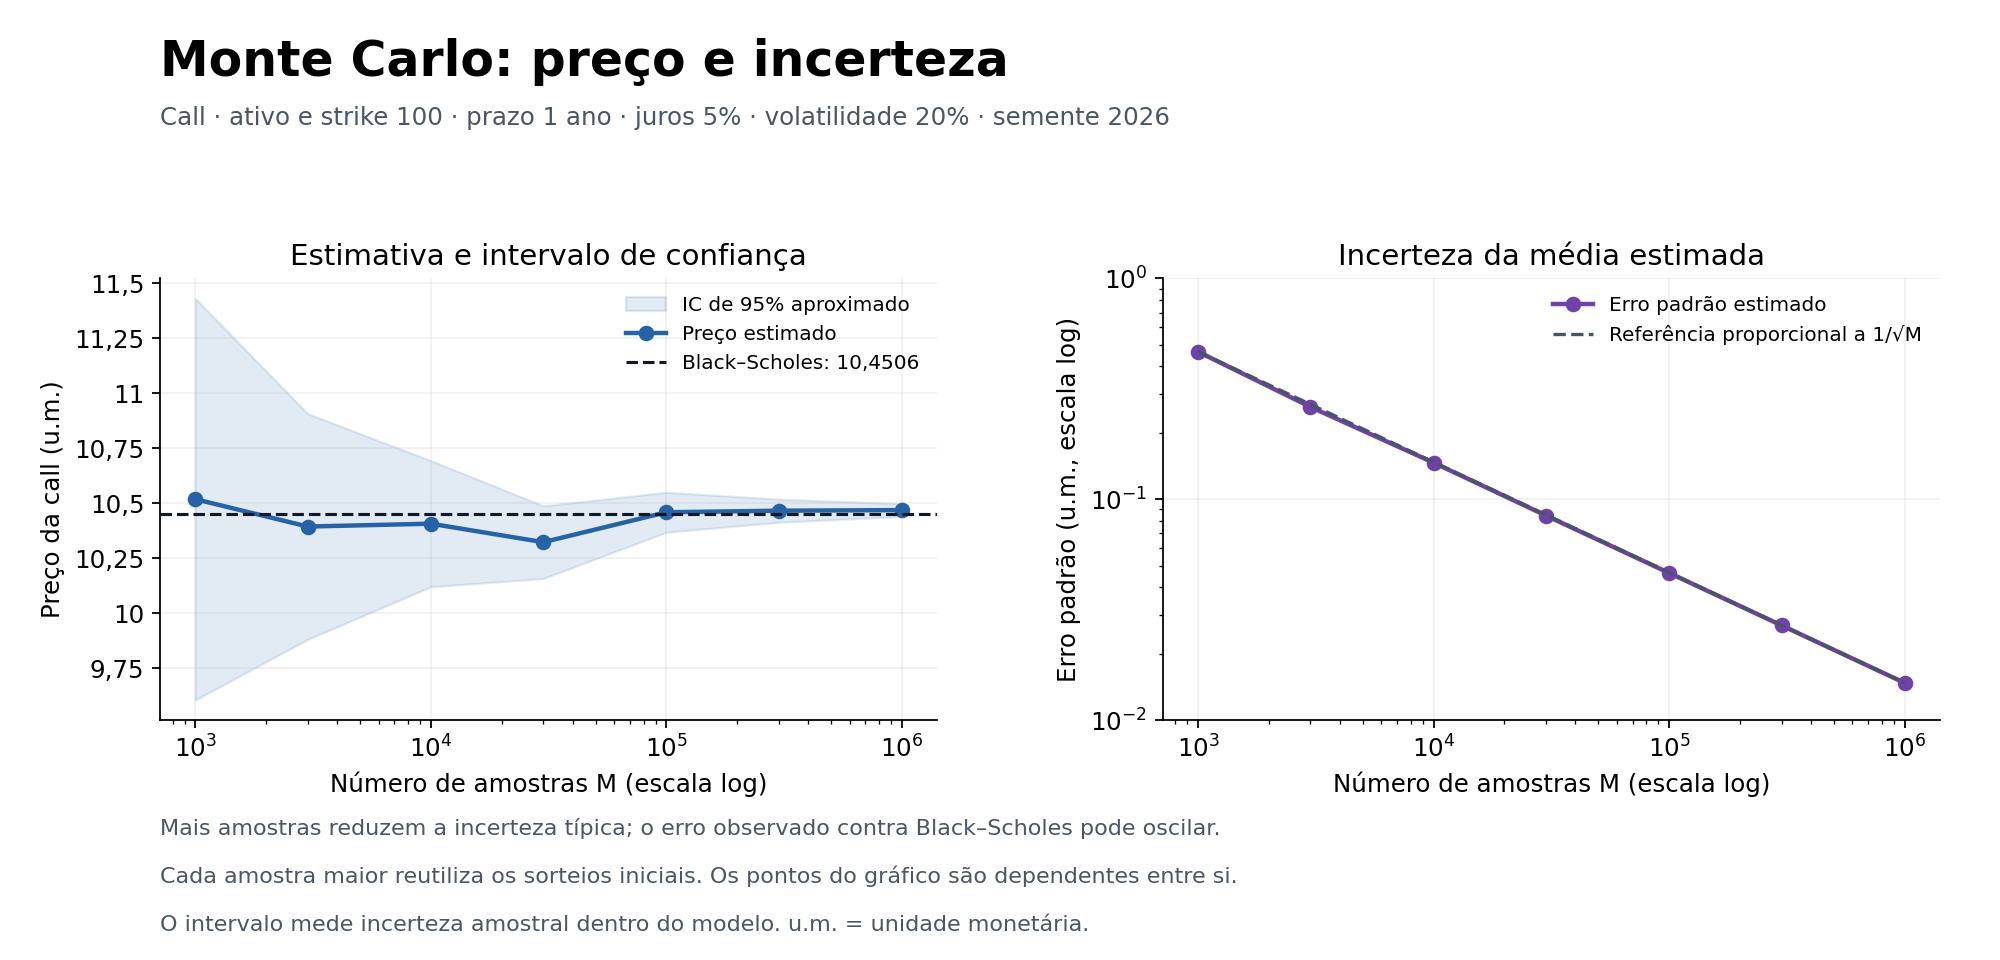

In [10]:
mc = plotters['monte_carlo']['run_experiment']()
save_report(mc, 'monte_carlo_results.json')
rows = []
for item in mc['call_estimates']:
    lo, hi = item['confidence_interval']
    rows.append((item['n_paths'], f"{item['price']:.8f}",
                 f"{item['standard_error']:.8f}", f'[{lo:.8f}; {hi:.8f}]'))
table(['Amostras', 'Call Monte Carlo', 'Erro padrão', 'IC95% aproximado'], rows)
figure(plotters['monte_carlo']['create_figure'](mc), 'monte_carlo_convergence.png')

A incerteza típica diminui com o tamanho da amostra; o erro padrão estimado e
o erro em relação ao preço analítico podem oscilar. A comparação com Black–Scholes permite distinguir a
incerteza de simulação de um possível erro de implementação.

Uma amostra com todos os pagamentos iguais a zero produz média e erro padrão
empíricos nulos. Para opções com baixa probabilidade de exercício, isso pode
significar apenas que a amostra não encontrou os eventos relevantes. Esse caso
é diferente de prazo ou volatilidade nulos, em que o pagamento é determinístico.

In [11]:
rare = {**parameters, 'strike': 200.0}
small = monte_carlo_price(**rare, n_paths=2, seed=0)
reference_rare = black_scholes_price(**rare)
assert small.price == 0.0 and reference_rare > 0.0
table(['Call com strike 200', 'Valor'], [
    ('Estimativa com duas observações', small.price),
    ('Intervalo empírico', small.confidence_interval),
    ('Preço Black–Scholes', f'{reference_rare:.10f}'),
])
put_mc = mc['put_estimate']
table(['Método', 'Call', 'Put'], [
    ('Black–Scholes', f'{call:.8f}', f'{put:.8f}'),
    ('CRR, 1.000 intervalos', f'{binomial_crr_price(**parameters,steps=1000):.8f}',
     f'{binomial_crr_price(**parameters,steps=1000,option_type="put"):.8f}'),
    ('Monte Carlo, 1.000.000 amostras', f"{mc['call_estimates'][-1]['price']:.8f}",
     f"{put_mc['price']:.8f}"),
])

| Call com strike 200 | Valor |
| --- | --- |
| Estimativa com duas observações | 0.0 |
| Intervalo empírico | (0.0, 0.0) |
| Preço Black–Scholes | 0.0047988351 |

| Método | Call | Put |
| --- | --- | --- |
| Black–Scholes | 10.45058357 | 5.57352602 |
| CRR, 1.000 intervalos | 10.44858410 | 5.57152655 |
| Monte Carlo, 1.000.000 amostras | 10.46905471 | 5.56110956 |

## Contabilidade do delta hedge

Considere o vendedor de uma call, que recebe o prêmio $p_0$ e assume a obrigação
de pagar $h_C(S_T)$. Uma carteira com $\delta_t$ ações e saldo de caixa $A_t$
tem valor $W_t=\delta_tS_t+A_t$. Enquanto a opção permanece aberta, o valor
líquido da posição combinada é $W_t-C(t,S_t)$.

Para uma pequena variação do ativo, mantendo as posições e o tempo fixos, a
sensibilidade dessa posição é

$$\frac{\partial}{\partial S}[\delta S+A-C(t,S)]
  =\delta-\frac{\partial C}{\partial S}.$$

A escolha $\delta=\Delta_C$ anula essa derivada. Trata-se de uma compensação
local: uma mudança finita de preço, o decorrer do tempo e a curvatura da opção
alteram o delta necessário. Na implementação, a quantidade de ações permanece
constante entre datas de negociação.

O preço do ativo é simulado nos instantes $t_i=iT/N$ por transições exatas:

$$S_{i+1}=S_i\exp\!\left[(r-\sigma^2/2)\Delta t
                          +\sigma\sqrt{\Delta t}\,Z_i\right].$$

A discretização refere-se às datas de negociação, não a uma aproximação de
Euler para o ativo. O caixa cresce continuamente à taxa $r$ entre essas datas.

Na montagem, a compra das ações é financiada pelo prêmio e pelo caixa:

$$\delta_0=\Delta_C(0,S_0),\qquad A_0=p_0-\delta_0S_0.$$

O valor negativo de $A_0$ representa um empréstimo. Nas datas interiores,

$$\delta_i=\Delta_C(t_i,S_i),\qquad
A_i=A_{i-1}e^{r\Delta t}-(\delta_i-\delta_{i-1})S_i.$$

Uma compra reduz o caixa; uma venda o aumenta. Os ajustes não recebem aportes
externos, caracterizando uma estratégia autofinanciada. No vencimento, as ações
são vendidas e o payoff é pago:

$$\mathrm{PnL}_T=A_{N-1}e^{r\Delta t}+\delta_{N-1}S_T-h_C(S_T).$$

O termo *PnL* designa o resultado financeiro da estratégia, em moeda do
vencimento. Após a liquidação, não restam ações nem obrigação da opção; o PnL
é o saldo final de caixa. Não se calcula um novo delta nessa data.

In [12]:
path = simulate_gbm_path(S, tau, r, sigma, steps=52, seed=2026)
hedge = delta_hedge_path(path, K, tau, r, sigma)
first, last = hedge.records[0], hedge.records[-1]
table(['Carteira de referência', 'Valor'], [
    ('Prêmio inicial', f'{hedge.initial_premium:.8f}'),
    ('Quantidade inicial de ações', f'{first.shares:.8f}'),
    ('Caixa inicial', f'{first.cash:.8f}'),
    ('Preço terminal do ativo', f'{last.spot:.8f}'),
    ('Payoff pago', f'{hedge.payoff:.8f}'),
    ('Resultado terminal', f'{hedge.terminal_pnl:.8f}'),
])
assert last.shares == 0 and last.option_value == 0
assert last.cash == last.net_value == hedge.terminal_pnl

| Carteira de referência | Valor |
| --- | --- |
| Prêmio inicial | 10.45058357 |
| Quantidade inicial de ações | 0.63683065 |
| Caixa inicial | -53.23248155 |
| Preço terminal do ativo | 83.61705636 |
| Payoff pago | 0.00000000 |
| Resultado terminal | -1.25067620 |

No início, aproximadamente 0,6368 ação custa 63,6831. O prêmio recebido,
10,4506, é complementado por uma dívida de 53,2325. Nessa trajetória, o ativo
termina abaixo do strike e a call não exige pagamento. Ainda assim, as compras,
vendas e juros acumulados deixam uma perda de aproximadamente 1,2507.
O payoff isolado não determina o resultado de toda a estratégia.

Cada registro é posterior às operações da data. A identidade contábil que
abrange montagem, ajustes e liquidação é

$$A_i=A_{i-1}+I_i-q_iS_i+F_i,$$

onde $q_i$ é a quantidade comprada, negativa em uma venda; $I_i$ são os juros;
e $F_i$ é o fluxo da opção: prêmio no início, zero no interior e payoff negativo
no fim. Antes da montagem, caixa e posição em ações são zero.

In [13]:
rows, previous_cash = [], 0.0
for i, row in enumerate(hedge.records):
    reconstructed = previous_cash+row.interest-row.trade*row.spot+row.option_cash_flow
    assert math.isclose(row.cash, reconstructed, abs_tol=1e-12)
    previous_cash = row.cash
    if i in [0,1,2,25,51,52]:
        rows.append((i, f'{row.time:.4f}', f'{row.spot:.4f}', f'{row.shares:.5f}',
                     f'{row.trade:.5f}', f'{row.interest:.5f}', f'{row.cash:.5f}',
                     f'{row.net_value:.5f}'))
table(['i', 'Tempo', 'Ativo', 'Ações', 'Negociação', 'Juros', 'Caixa', 'Valor líquido'], rows)
dt = tau / 52
financed_gains = math.fsum(
    before.shares * (after.spot-before.spot*math.exp(r*dt))
    * math.exp(r*(tau-after.time))
    for before,after in zip(hedge.records[:-1],hedge.records[1:])
)
pnl_from_gains = hedge.initial_premium*math.exp(r*tau)+financed_gains-hedge.payoff
assert math.isclose(pnl_from_gains, hedge.terminal_pnl, abs_tol=1e-10)
print(f'Resíduo da identidade dos ganhos financiados: {pnl_from_gains-hedge.terminal_pnl:.3e}')

| i | Tempo | Ativo | Ações | Negociação | Juros | Caixa | Valor líquido |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.0000 | 100.0000 | 0.63683 | 0.63683 | 0.00000 | -53.23248 | 0.00000 |
| 1 | 0.0192 | 102.4897 | 0.68110 | 0.04427 | -0.05121 | -57.82086 | 0.01829 |
| 2 | 0.0385 | 104.8617 | 0.72081 | 0.03971 | -0.05562 | -62.04099 | 0.04291 |
| 25 | 0.4808 | 97.7903 | 0.53870 | 0.16835 | -0.02973 | -47.40127 | -0.50742 |
| 51 | 0.9808 | 81.1879 | 0.00000 | -0.00000 | -0.00120 | -1.24947 | -1.24947 |
| 52 | 1.0000 | 83.6171 | 0.00000 | -0.00000 | -0.00120 | -1.25068 | -1.25068 |

Resíduo da identidade dos ganhos financiados: 9.748e-14


Uma verificação independente da recursão do caixa utiliza os ganhos das ações
líquidos de seu financiamento, todos transportados à mesma data:

$$\mathrm{PnL}_T=p_0e^{rT}
 +\sum_{i=0}^{N-1}\delta_i(S_{i+1}-S_ie^{r\Delta t})e^{r(T-t_{i+1})}
 -h_C(S_T).$$

O experimento de referência repete a estratégia em 2.000 trajetórias com 52
intervalos. As sementes são $2026+j$, para $j=0,\ldots,1999$. Essa amostra
descreve a distribuição do erro de replicação sob o modelo.

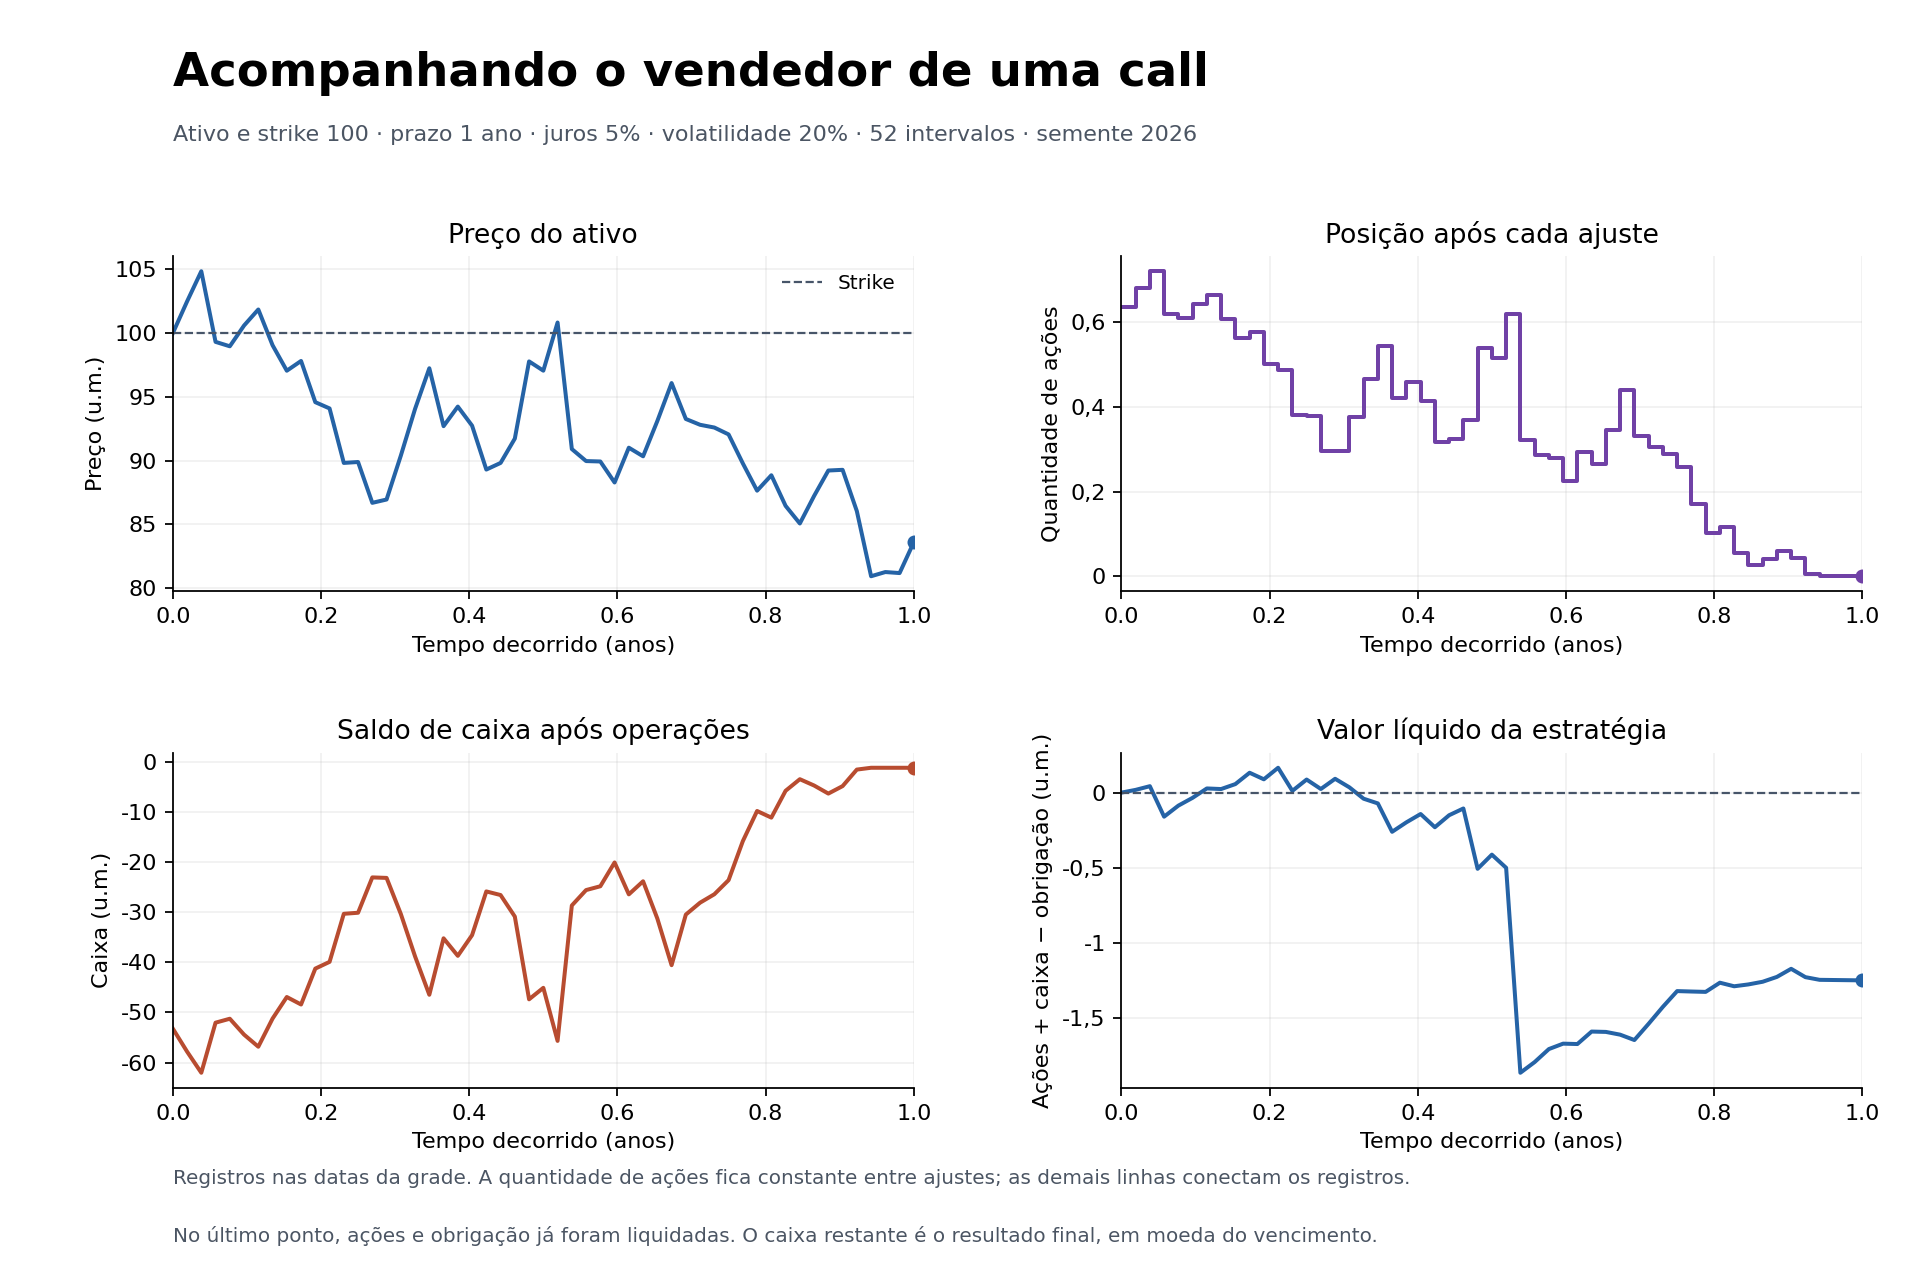

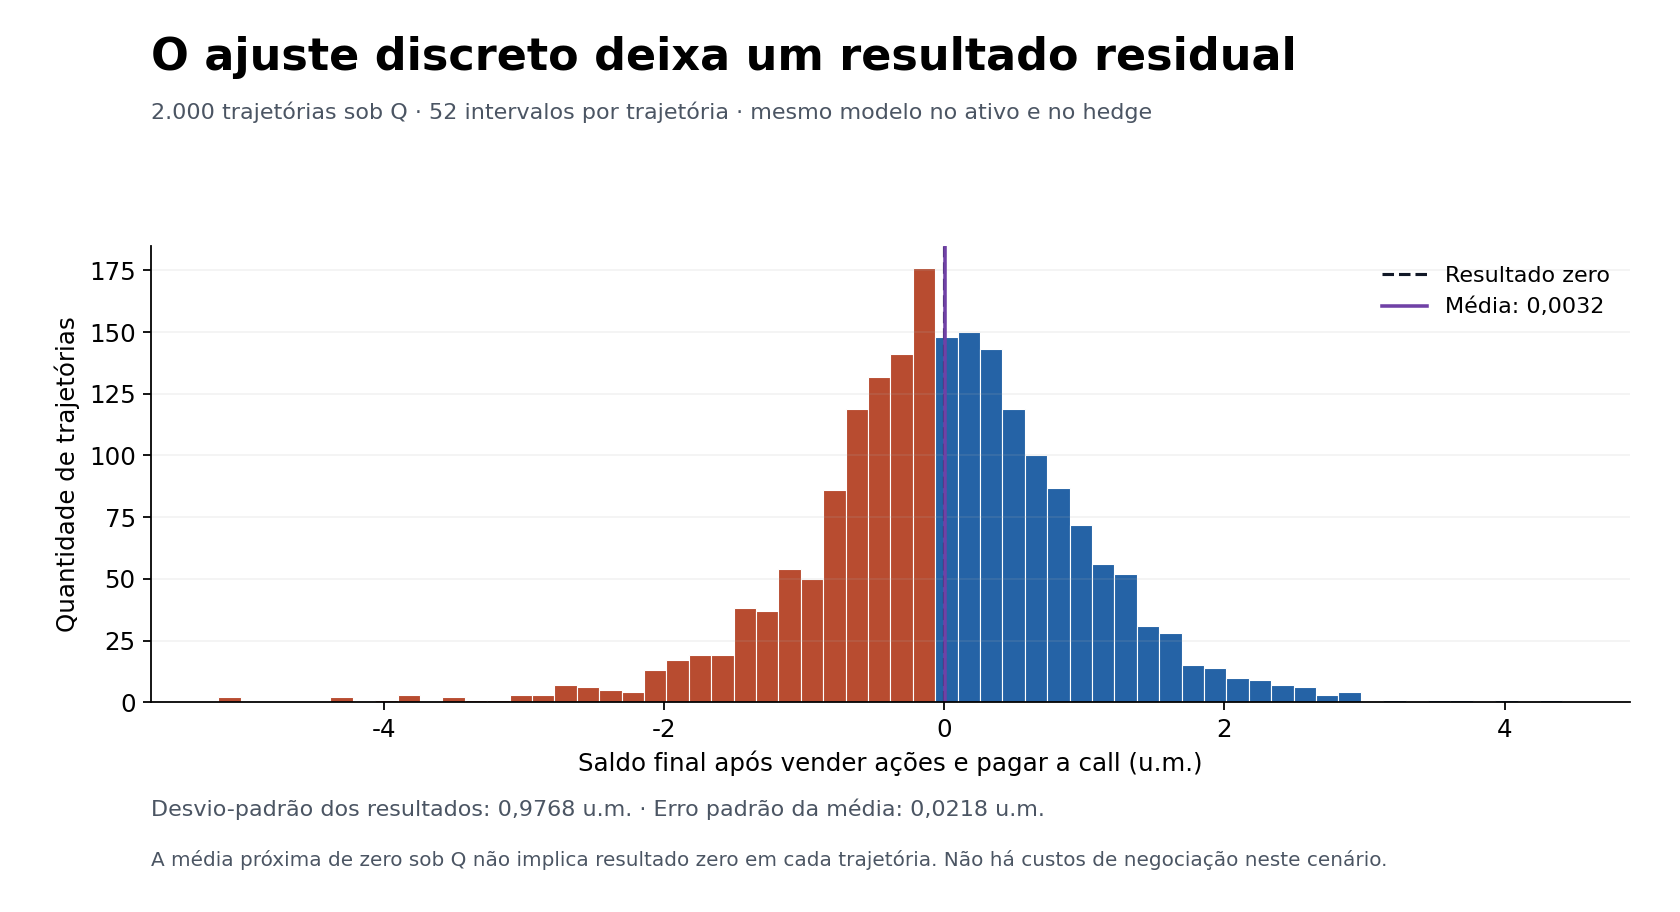

| Estatística | Valor |
| --- | --- |
| Média | 0.00319027 |
| Desvio padrão | 0.97684312 |
| Erro padrão da média | 0.02184288 |
| IC95% da média | [-0.03962098, 0.04600152] |

In [14]:
hedge_data = plotters['delta_hedge']['run_experiment']()
save_report(hedge_data, 'delta_hedge_results.json')
figure(plotters['delta_hedge']['create_path_figure'](hedge_data), 'delta_hedge_path.png')
figure(plotters['delta_hedge']['create_pnl_figure'](hedge_data), 'delta_hedge_pnl.png')
summary = hedge_data['summary']
table(['Estatística', 'Valor'], [
    ('Média', f"{summary['mean_pnl']:.8f}"),
    ('Desvio padrão', f"{summary['std_pnl']:.8f}"),
    ('Erro padrão da média', f"{summary['mean_standard_error']:.8f}"),
    ('IC95% da média', str([round(x,8) for x in summary['mean_confidence_interval_95_approx']])),
])

As linhas dos gráficos de ativo, caixa e valor líquido conectam os registros
observados. A posição em ações é constante entre ajustes, representada por
degraus. O último registro já contém a liquidação; nele, valor líquido e caixa
coincidem com o PnL.

A média próxima de zero é compatível com o prêmio Black–Scholes e a simulação
sob $\mathbb Q$. Ela não implica replicação exata em cada trajetória. O ajuste
discreto deixa uma dispersão que não desaparece ao aumentar apenas a quantidade
de trajetórias Monte Carlo.

## Comparações com trajetórias comuns

Os experimentos de frequência comparam 12, 52 e 252 intervalos por ano.
Para cada índice da amostra, uma única trajetória é gerada em 3.276 intervalos,
o mínimo múltiplo comum dessas frequências. As estratégias recebem subgrades
uniformes da mesma trajetória, com saltos de 273, 63 e 13 índices.

Os preços inicial e terminal são idênticos entre cenários pareados, assim como
os preços de datas compartilhadas. As três subgrades não são aninhadas entre
si. Reutilizar apenas a mesma semente em simulações separadas com números
diferentes de intervalos não produziria essa correspondência.

São usadas 2.000 trajetórias-mestras, com sementes $2026+j$. Essas amostras
diferem das trajetórias de 52 intervalos geradas diretamente no experimento
de referência.

In [15]:
experiments = run_hedging_experiments(n_paths=2000, seed_start=2026)
save_report(experiments, 'hedging_experiments_results.json')
scenarios = {item['id']: item for item in experiments['scenarios']}
paths = experiments['example_paths']
assert experiments['master_steps'] == math.lcm(12,52,252) == 3276
assert paths['12'][3] == paths['52'][13] == paths['252'][63]
assert paths['12'][-1] == paths['52'][-1] == paths['252'][-1]
table(['Intervalos', 'Observações', 'Preço em t=1/4', 'Preço em T'],
      [(n,len(paths[str(n)]),f'{paths[str(n)][n//4]:.6f}',f'{paths[str(n)][-1]:.6f}')
       for n in experiments['frequencies']])

| Intervalos | Observações | Preço em t=1/4 | Preço em T |
| --- | --- | --- | --- |
| 12 | 13 | 107.182141 | 119.053993 |
| 52 | 53 | 107.182141 | 119.053993 |
| 252 | 253 | 107.182141 | 119.053993 |

### Frequência e erro de replicação

Com prêmio correto, mesma volatilidade no ativo e no delta, e custo zero,
a frequência altera a distribuição dos resultados da replicação. A média,
o desvio padrão e a raiz do erro quadrático médio (RMSE) descrevem aspectos
distintos dessa distribuição. Para resultados $X_1,\ldots,X_M$,

$$\bar X=\frac1M\sum_jX_j,\qquad
s_X^2=\frac1{M-1}\sum_j(X_j-\bar X)^2,$$

$$\operatorname{RMSE}=\sqrt{\frac1M\sum_jX_j^2},\qquad
\operatorname{RMSE}^2=\bar X^2+\frac{M-1}{M}s_X^2.$$

O desvio padrão mede dispersão em torno da média. O RMSE mede distância de
zero e, portanto, incorpora também o deslocamento da média.

| Intervalos | Média | Desvio padrão | RMSE |
| --- | --- | --- | --- |
| 12 | -0.041602 | 1.935844 | 1.935807 |
| 52 | 0.011389 | 0.932139 | 0.931975 |
| 252 | 0.005652 | 0.412408 | 0.412344 |

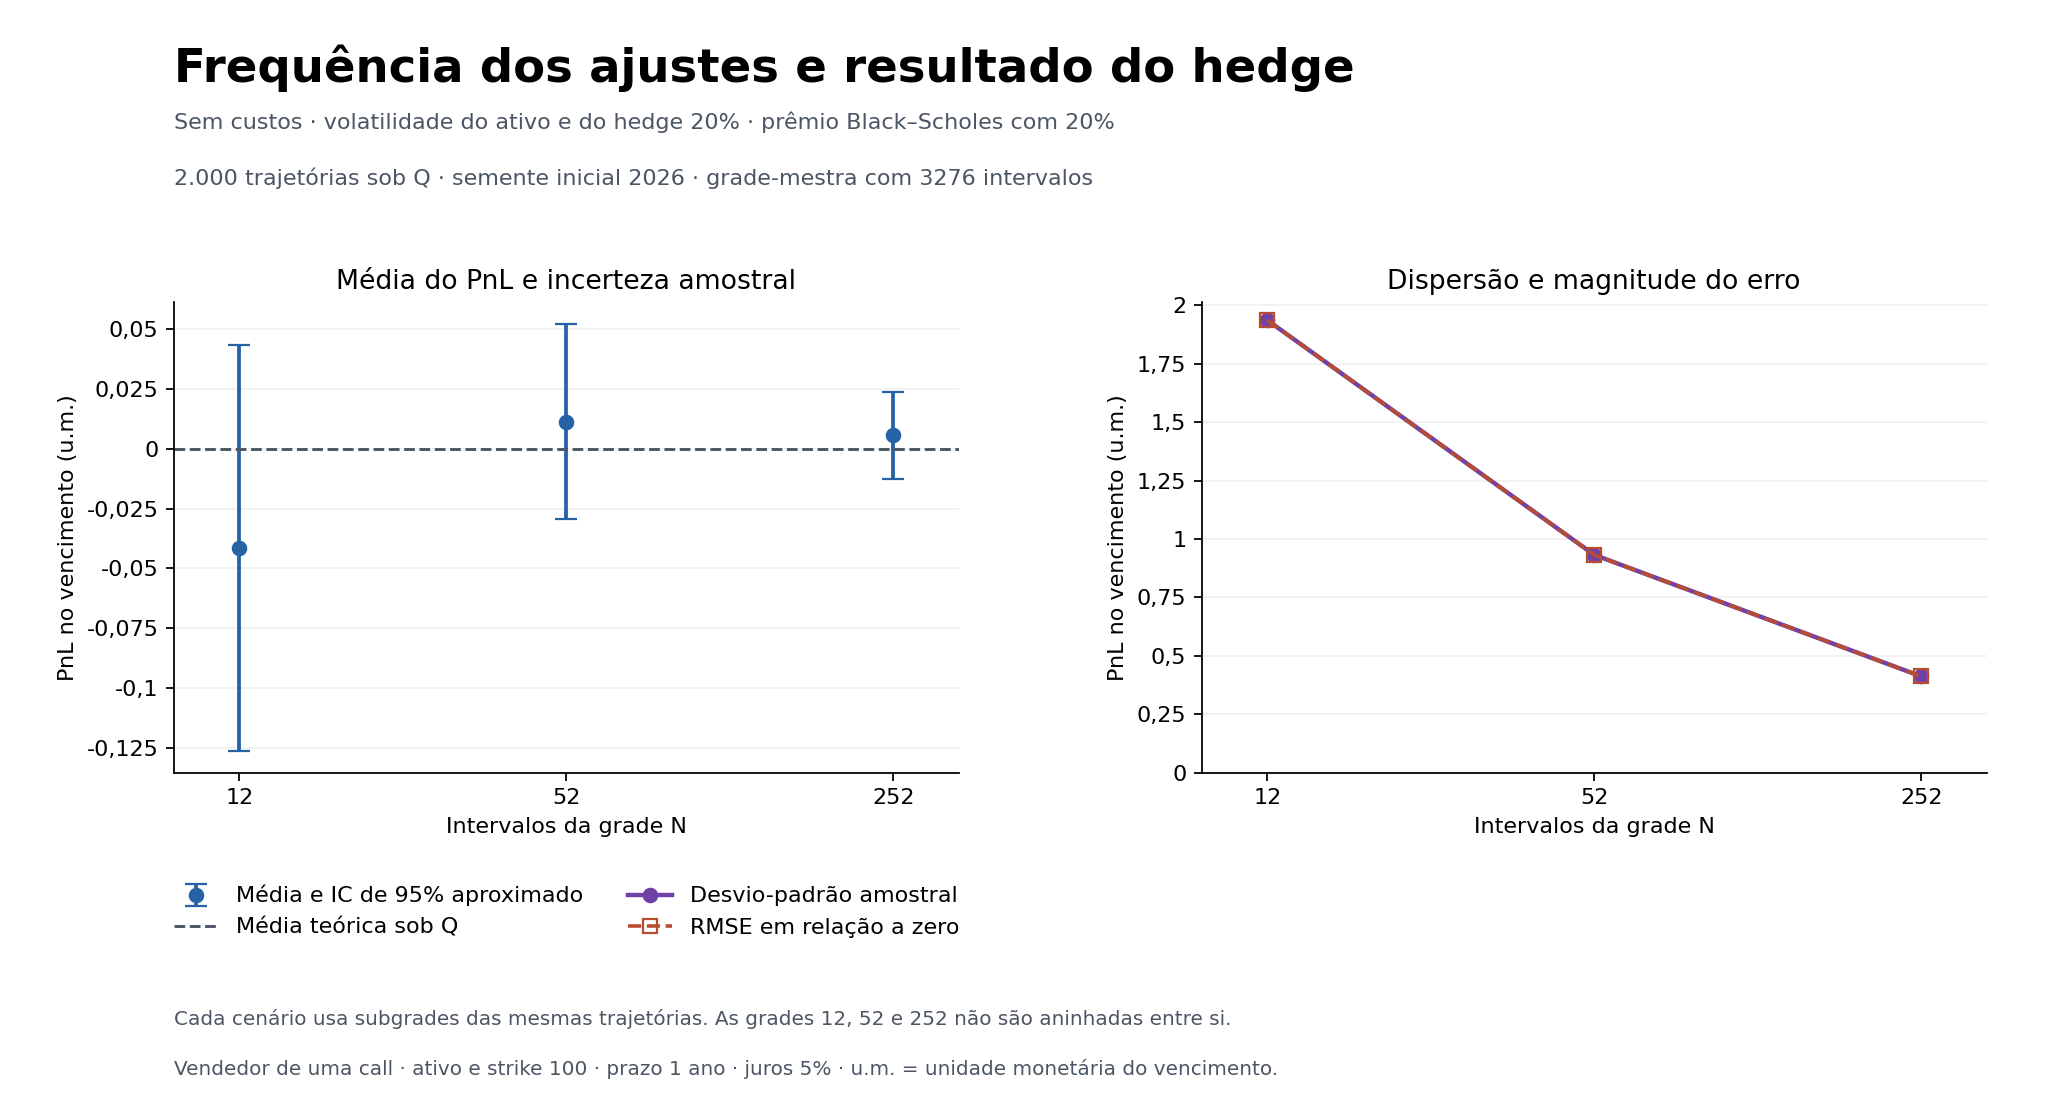

In [16]:
rows = []
for n in experiments['frequencies']:
    q = scenarios[f'n{n}_cost0bp']['summary']
    rows.append((n, f"{q['mean_pnl']:.6f}", f"{q['std_pnl']:.6f}", f"{q['rmse_pnl']:.6f}"))
    assert math.isclose(q['rmse_pnl']**2,
                        q['mean_pnl']**2 + (2000-1)/2000*q['std_pnl']**2, rel_tol=1e-12)
table(['Intervalos', 'Média', 'Desvio padrão', 'RMSE'], rows)
figure(plotters['hedging_experiments']['create_frequency_figure'](experiments), 'hedging_frequency.png')

Na amostra, o desvio padrão cai de aproximadamente 1,9358 para 0,4124 entre
12 e 252 intervalos. As médias permanecem compatíveis com zero. A maior
frequência acompanha melhor as mudanças do delta neste modelo; essa
observação não implica melhora em todas as trajetórias individuais.

### Custos proporcionais de negociação

O custo de uma negociação de $q_i$ ações ao preço $S_i$ é

$$c_i=\kappa|q_i|S_i.$$

A cobrança inclui montagem, ajustes e liquidação final. Os níveis de $\kappa$
são 0, 5, 10 e 20 pontos-base do valor negociado, equivalentes a 0%, 0,05%,
0,10% e 0,20%. Um ponto-base é $0,01\%$. As taxas são parâmetros do experimento,
não cotações de despesas de uma corretora.

O custo é debitado do caixa no momento da negociação:

$$A_i=A_{i-1}+I_i-q_iS_i+F_i-c_i.$$

O prêmio e a regra do delta são mantidos. Não há ajuste automático no preço
cobrado pela opção para cobrir as despesas. A soma nominal $\sum_i c_i$ registra
os pagamentos nas respectivas datas; seu efeito sobre o resultado terminal é

$$C_T^{\mathrm{custos}}=\sum_i c_i e^{r(T-t_i)}.$$

Para as mesmas posições e o mesmo prêmio, vale a identidade
$\mathrm{PnL}_{\kappa}=\mathrm{PnL}_0-C_T^{\mathrm{custos}}$. O custo já está
incluído no caixa retornado pela função; subtraí-lo novamente duplicaria a
despesa.

| Trajetória com 52 intervalos e custo de 10 pb | Valor |
| --- | --- |
| PnL sem custos | 0.63070794 |
| PnL com custos | 0.31798864 |
| Custos nominais | 0.30544961 |
| Custos capitalizados até T | 0.31271930 |

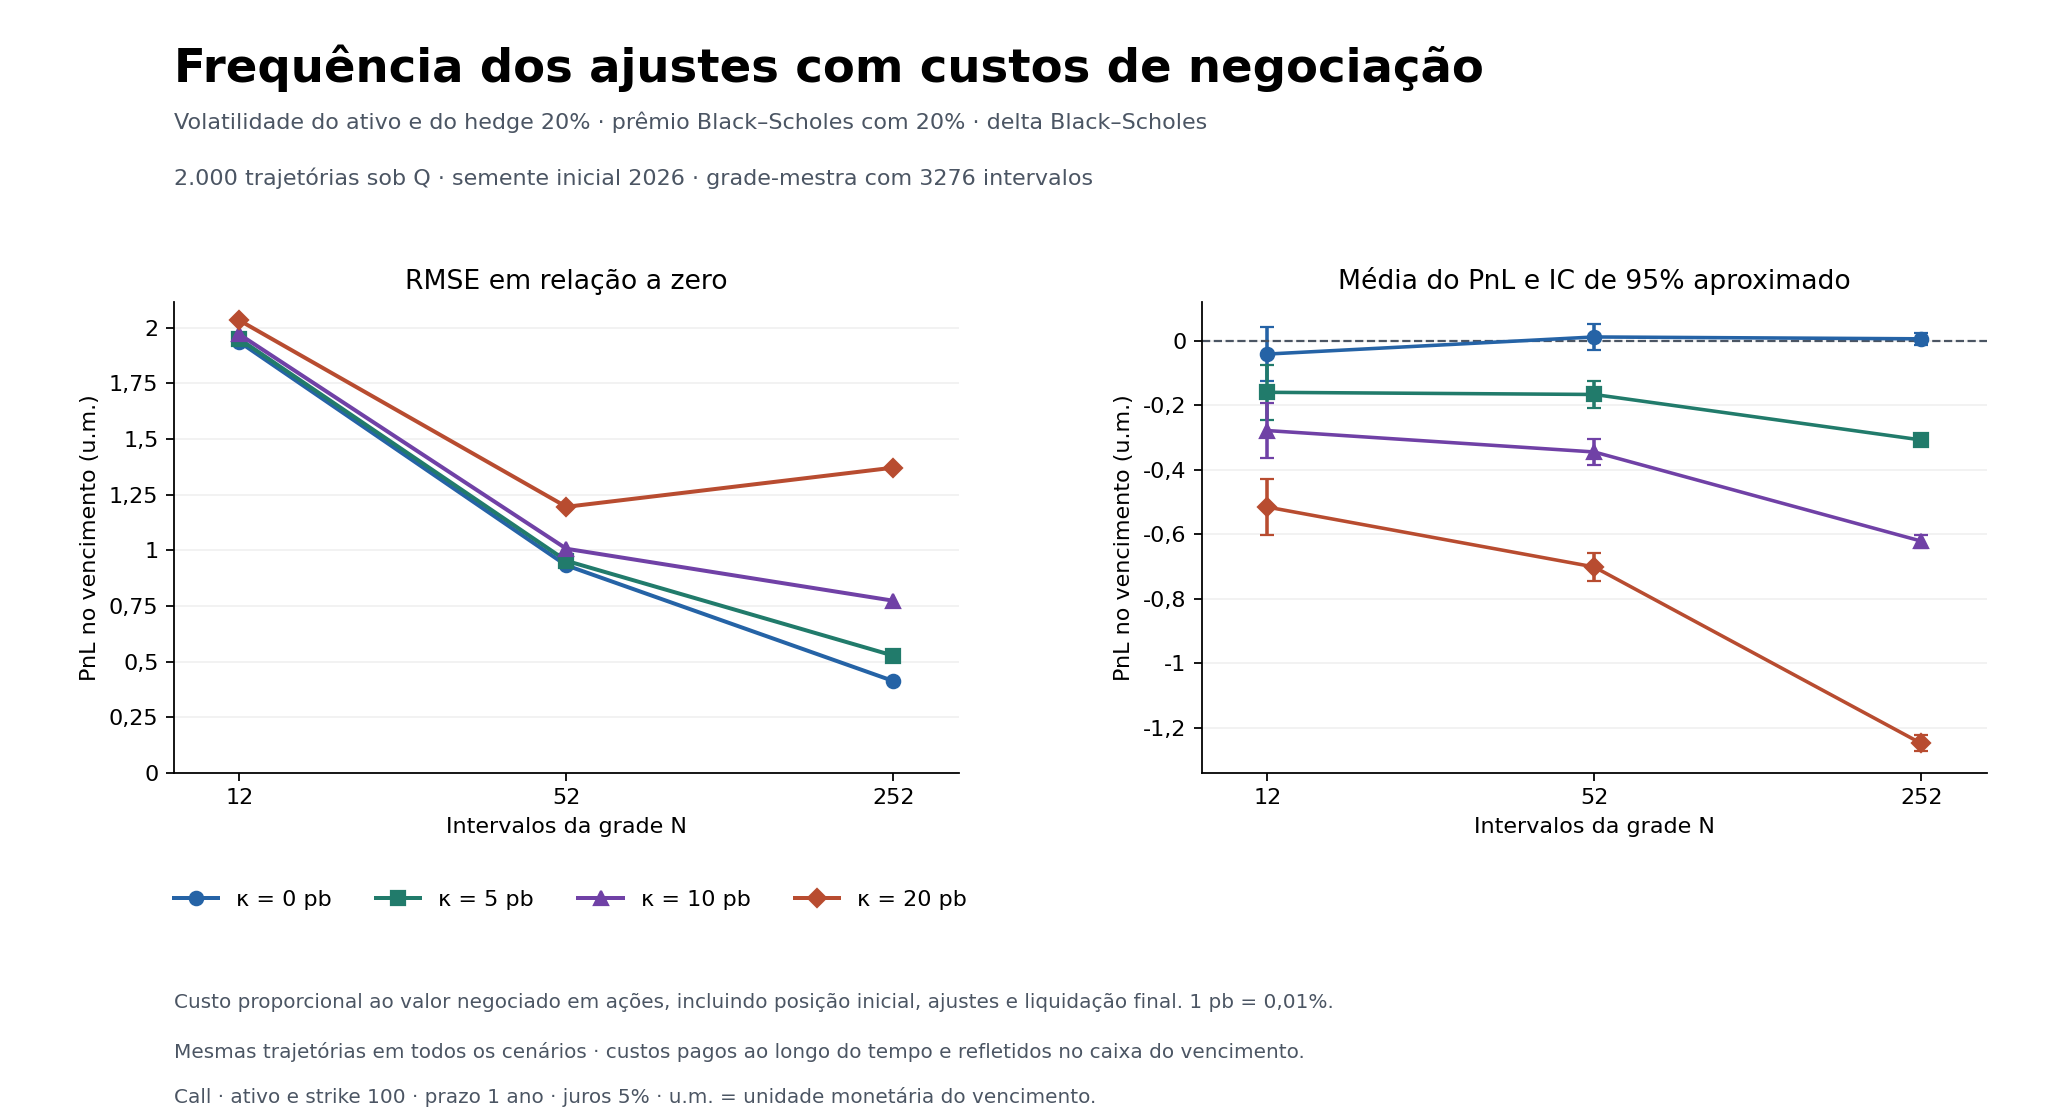

In [17]:
sample_path = paths['52']
base_hedge = delta_hedge_path(sample_path,K,tau,r,sigma)
cost_hedge = delta_hedge_path(sample_path,K,tau,r,sigma,transaction_cost_rate=0.001)
assert math.isclose(base_hedge.terminal_pnl-cost_hedge.terminal_pnl,
                    cost_hedge.terminal_transaction_cost, abs_tol=1e-10)
independent_cost = math.fsum(q.transaction_cost*math.exp(r*(tau-q.time))
                             for q in cost_hedge.records)
assert math.isclose(independent_cost,cost_hedge.terminal_transaction_cost,abs_tol=1e-10)
table(['Trajetória com 52 intervalos e custo de 10 pb', 'Valor'], [
    ('PnL sem custos', f'{base_hedge.terminal_pnl:.8f}'),
    ('PnL com custos', f'{cost_hedge.terminal_pnl:.8f}'),
    ('Custos nominais', f'{cost_hedge.total_transaction_cost:.8f}'),
    ('Custos capitalizados até T', f'{cost_hedge.terminal_transaction_cost:.8f}'),
])
figure(plotters['hedging_experiments']['create_costs_figure'](experiments), 'hedging_costs.png')

In [18]:
table(['Intervalos', 'Custo (pb)', 'Média', 'Desvio padrão', 'RMSE', 'Custo médio em T'],
      [(n,bp,f"{scenarios[f'n{n}_cost{bp}bp']['summary']['mean_pnl']:.6f}",
             f"{scenarios[f'n{n}_cost{bp}bp']['summary']['std_pnl']:.6f}",
             f"{scenarios[f'n{n}_cost{bp}bp']['summary']['rmse_pnl']:.6f}",
             f"{scenarios[f'n{n}_cost{bp}bp']['summary']['mean_terminal_cost']:.6f}")
       for n in [12,52,252] for bp in [5,10,20]])

| Intervalos | Custo (pb) | Média | Desvio padrão | RMSE | Custo médio em T |
| --- | --- | --- | --- | --- | --- |
| 12 | 5 | -0.160124 | 1.942951 | 1.949054 | 0.118522 |
| 12 | 10 | -0.278646 | 1.950476 | 1.969796 | 0.237044 |
| 12 | 20 | -0.515691 | 1.966756 | 2.032765 | 0.474089 |
| 52 | 5 | -0.166816 | 0.938073 | 0.952558 | 0.178205 |
| 52 | 10 | -0.345021 | 0.946064 | 1.006791 | 0.356410 |
| 52 | 20 | -0.701431 | 0.968001 | 1.195224 | 0.712820 |
| 252 | 5 | -0.307778 | 0.427219 | 0.526453 | 0.313430 |
| 252 | 10 | -0.621209 | 0.460514 | 0.773219 | 0.626861 |
| 252 | 20 | -1.248070 | 0.567931 | 1.371154 | 1.253721 |

Com custo de 20 pontos-base, a grade de 252 intervalos tem desvio padrão menor
que a de 52, mas perda média maior. Seus RMSEs são aproximadamente 1,3712 e
1,1952, respectivamente. Nesse cenário, a redução da dispersão não compensa
o deslocamento da média para valores negativos segundo o critério quadrático.

A comparação restringe-se às frequências, taxas e políticas testadas. Não
estabelece uma frequência ótima universal, nem implementa uma política de
negociação otimizada para custos.

### Volatilidade do hedge e prêmio recebido

O ativo é gerado com volatilidade de 20%, enquanto os deltas são calculados com
$\sigma_h\in\{15\%,20\%,25\%\}$. Fixam-se 252 intervalos e custo zero. Duas
convenções distinguem o erro na regra de negociação do efeito do prêmio:

| Convenção | Prêmio recebido | Volatilidade usada no delta |
|---|---|---|
| Prêmio fixo | $C(\sigma=20\%)$ | $\sigma_h$ |
| Prêmio do modelo de hedge | $C(\sigma_h)$ | $\sigma_h$ |

Na primeira convenção, o prêmio correto é informado por `initial_premium`.
Na segunda, usa-se o valor padrão da API, calculado com a volatilidade do
hedge. Mudar apenas o prêmio desloca todos os resultados pelo mesmo valor:

$$\mathrm{PnL}_{\mathrm{modelo}}-\mathrm{PnL}_{\mathrm{fixo}}
 =\left[C(\sigma_h)-C(20\%)\right]e^{rT}.$$

O desvio padrão permanece igual entre essas duas convenções para um mesmo
$\sigma_h$, embora a média e o RMSE possam mudar.

| Vol. do hedge | Prêmio | Valor recebido | Média do PnL | Média teórica | Desvio padrão |
| --- | --- | --- | --- | --- | --- |
| 15% | Fixo, 20% | 10.450584 | 0.036293 | 0.000000 | 0.952730 |
| 15% | Modelo do hedge | 8.591658 | -1.917941 | -1.954234 | 0.952730 |
| 20% | Fixo, 20% | 10.450584 | 0.005652 | 0.000000 | 0.412408 |
| 20% | Modelo do hedge | 10.450584 | 0.005652 | 0.000000 | 0.412408 |
| 25% | Fixo, 20% | 10.450584 | -0.014593 | 0.000000 | 0.796646 |
| 25% | Modelo do hedge | 12.335999 | 1.967490 | 1.982083 | 0.796646 |

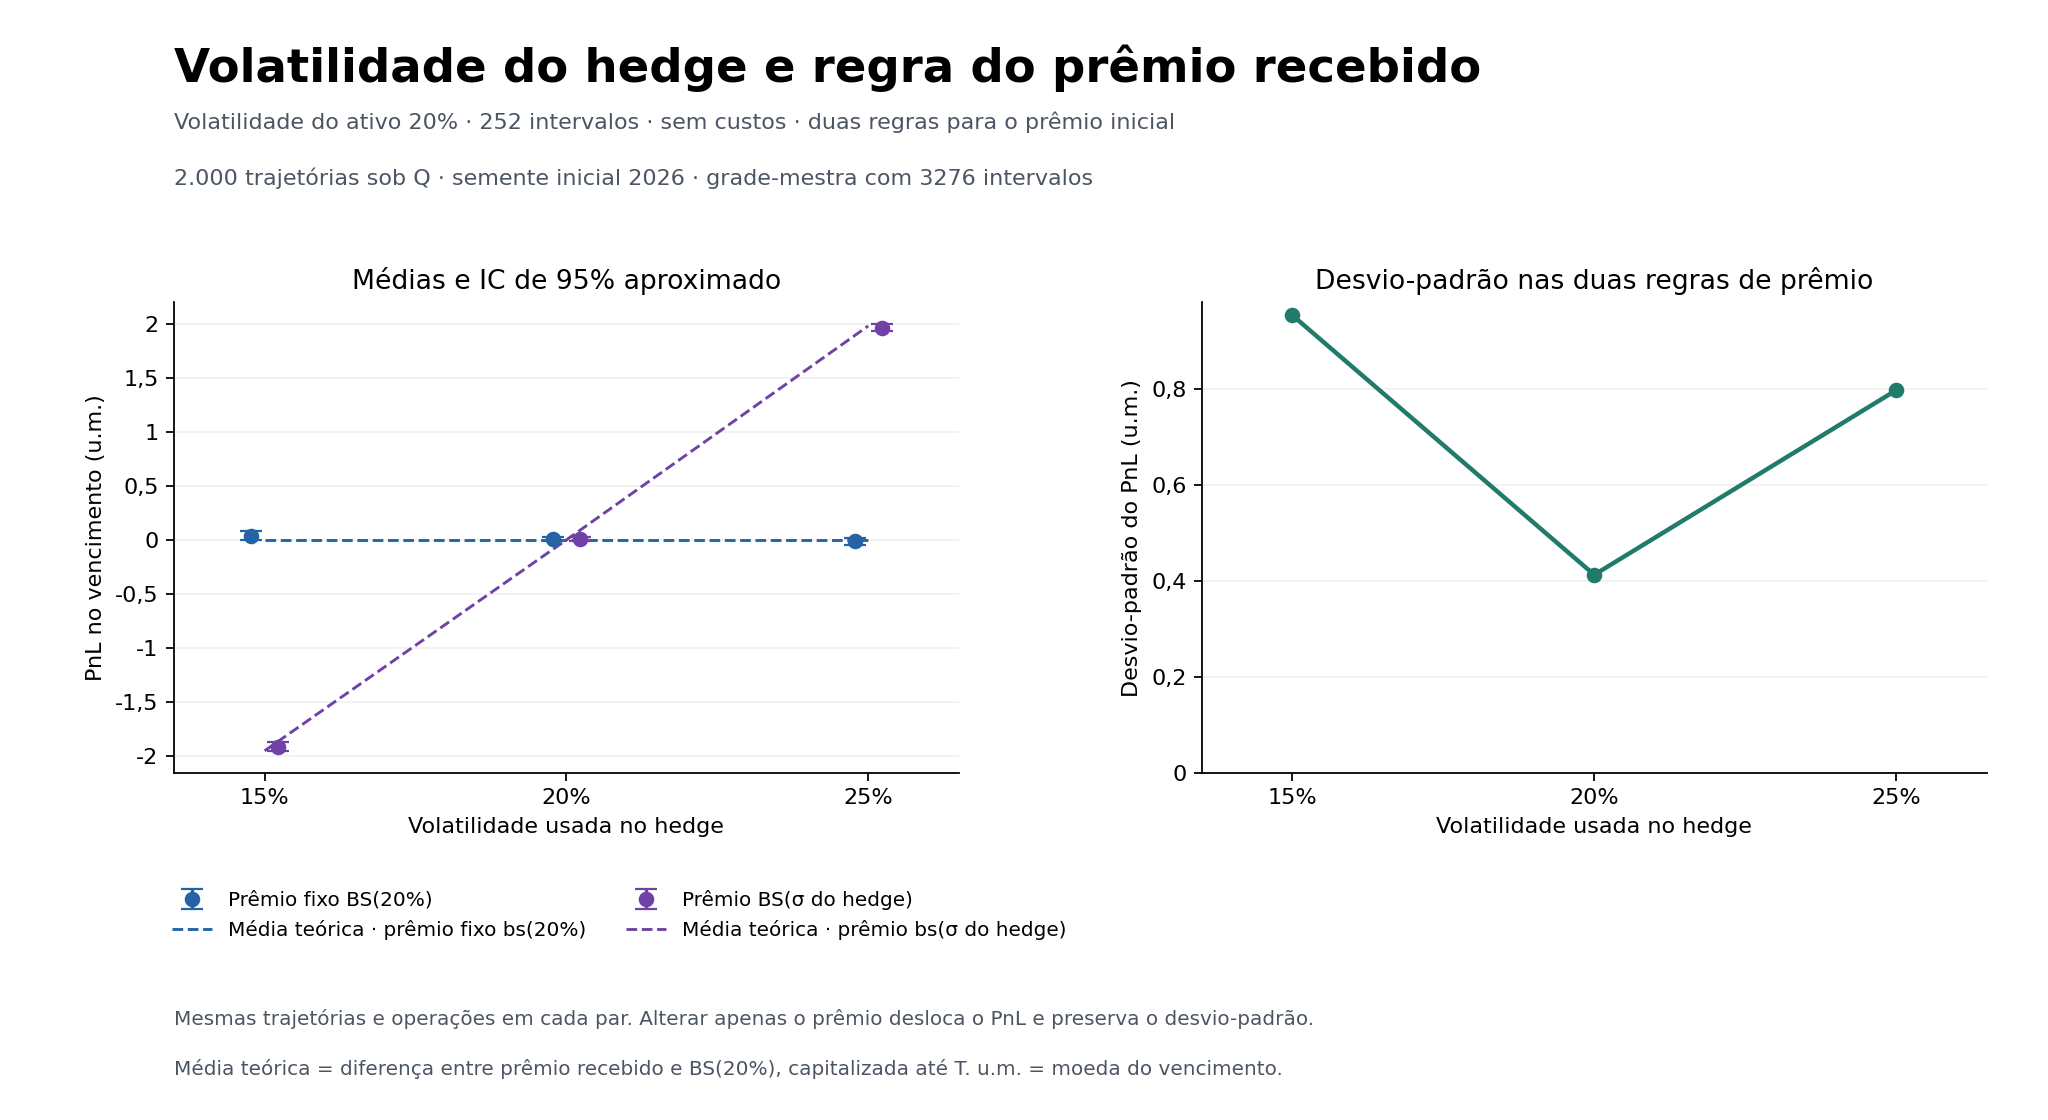

In [19]:
fixed = delta_hedge_path(paths['252'],K,tau,r,0.15,initial_premium=call)
quoted = delta_hedge_path(paths['252'],K,tau,r,0.15)
shift = (quoted.initial_premium-fixed.initial_premium)*math.exp(r*tau)
assert math.isclose(quoted.terminal_pnl-fixed.terminal_pnl,shift,abs_tol=1e-10)
assert [q.shares for q in fixed.records] == [q.shares for q in quoted.records]
rows = []
for pct in [15,20,25]:
    for rule,label in [('fixed_true_model','Fixo, 20%'),('hedge_model','Modelo do hedge')]:
        item = scenarios[f'vol{pct}_{rule}']
        q = item['summary']
        rows.append((f'{pct}%',label,f"{item['initial_premium']:.6f}",
                     f"{q['mean_pnl']:.6f}",f"{item['theoretical_mean_without_costs']:.6f}",
                     f"{q['std_pnl']:.6f}"))
    a = scenarios[f'vol{pct}_fixed_true_model']['summary']['std_pnl']
    b = scenarios[f'vol{pct}_hedge_model']['summary']['std_pnl']
    assert math.isclose(a,b,abs_tol=1e-10)
table(['Vol. do hedge','Prêmio','Valor recebido','Média do PnL','Média teórica','Desvio padrão'],rows)
figure(plotters['hedging_experiments']['create_volatility_figure'](experiments), 'hedging_volatility.png')

Sob $\mathbb Q$, os ganhos descontados de uma estratégia previsível e
autofinanciada têm esperança zero nas condições deste modelo. Sem custos,

$$\mathbb E^{\mathbb Q}[\mathrm{PnL}_T]
  =\left[p_0-C(20\%)\right]e^{rT}.$$

Com prêmio correto e fixo, a expectativa permanece zero mesmo quando a
volatilidade usada no delta está incorreta. O efeito aparece na distribuição
dos resultados. Na amostra, o desvio padrão é aproximadamente 0,9527 para
$\sigma_h=15\%$, 0,4124 para 20% e 0,7966 para 25%.

Quando o prêmio também muda, a média reflete a diferença de preço inicial.
Os resultados com prêmio maior pressupõem que a opção foi efetivamente
vendida por esse valor; não demonstram a existência de compradores dispostos
a aceitá-lo no mercado.

A marcação intermediária `option_value` utiliza $\sigma_h$. Com prêmio fixo
e volatilidade incorreta, o valor líquido inicial pode diferir de zero pela
diferença entre o prêmio recebido e essa marcação. As comparações econômicas
do estudo utilizam o resultado terminal, após liquidar a obrigação.

## Incerteza estatística e verificações

Os cenários compartilham trajetórias. A comparação de médias deve, portanto,
usar diferenças pareadas, sem tratá-los como amostras independentes. Para
comparar PnLs, define-se $D_j=X_{A,j}-X_{B,j}$; para comparar erros quadráticos,
$D_j=X_{A,j}^2-X_{B,j}^2$. O erro padrão da média das diferenças é
$s_D/\sqrt M$.

Os intervalos normais de 95% são aproximações para cada comparação, não
intervalos simultâneos para todo o conjunto de experimentos. Tampouco são
faixas contendo 95% dos resultados individuais.

In [20]:
def scenario_label(identifier):
    item = scenarios[identifier]
    return f"N={item['steps']}, custo={item['transaction_cost_rate']*10000:.0f} pb"

quantities = {'pnl': 'PnL (u.m.)', 'squared_pnl': 'PnL² (u.m.²)'}
table(['Cenário A','Cenário B','Medida A − B','Diferença média','IC95% aproximado'],
      [(scenario_label(p['left_id']),scenario_label(p['right_id']),quantities[p['quantity']],f"{p['mean_difference']:.6f}",
        str([round(x,6) for x in p['confidence_interval_95_approx']]))
       for p in experiments['paired_comparisons']])
for item in experiments['scenarios']:
    samples = item['terminal_pnls']
    assert len(samples) == experiments['n_paths']
    assert math.isclose(statistics.mean(samples),item['summary']['mean_pnl'],abs_tol=1e-12)
assert experiments['checks']['max_cost_identity_error'] < 1e-10
assert experiments['checks']['max_premium_identity_error'] < 1e-10
table(['Identidade contábil','Maior resíduo absoluto'],
      [('Custos capitalizados',f"{experiments['checks']['max_cost_identity_error']:.3e}"),
       ('Deslocamento do prêmio',f"{experiments['checks']['max_premium_identity_error']:.3e}")])

| Cenário A | Cenário B | Medida A − B | Diferença média | IC95% aproximado |
| --- | --- | --- | --- | --- |
| N=252, custo=0 pb | N=12, custo=0 pb | PnL² (u.m.²) | -3.577323 | [-4.009563, -3.145083] |
| N=252, custo=10 pb | N=12, custo=10 pb | PnL² (u.m.²) | -3.282230 | [-3.734206, -2.830254] |
| N=52, custo=10 pb | N=52, custo=0 pb | PnL (u.m.) | -0.356410 | [-0.36031, -0.35251] |

| Identidade contábil | Maior resíduo absoluto |
| --- | --- |
| Custos capitalizados | 3.721e-13 |
| Deslocamento do prêmio | 3.402e-13 |

## Implementação e limites

O núcleo usa a biblioteca padrão do Python. A árvore CRR requer tempo
$O(N^2)$ e memória $O(N)$; a estimativa Monte Carlo usa tempo $O(M)$ e memória
$O(1)$, atualizando média e variância incrementalmente. A trajetória e o
registro completo de hedge usam tempo e memória $O(N)$. Os experimentos
armazenam as amostras terminais para permitir comparações pareadas e auditoria.

Os testes cobrem paridade put–call, fronteiras determinísticas, sensibilidades
por diferenças finitas, recorrência CRR, estatísticas de Monte Carlo,
preservação do gerador aleatório global, autofinanciamento, custos,
liquidação e correspondência das trajetórias entre cenários. A reprodução
requer os mesmos parâmetros, sementes e ambiente; os algoritmos de `random`
não têm garantia de identidade entre todas as versões de Python.
O parâmetro `seed_start` dos experimentos é não negativo, evitando a colisão
entre sementes inteiras de sinais opostos no gerador utilizado.

Os preços são calculados em ponto flutuante. Escalas monetárias ou parâmetros
extremos podem causar perda de precisão, cancelamento ou arredondamento a
zero. Uma variância amostral extremamente pequena pode ser arredondada a zero;
o resultado não deve ser interpretado como precisão exata fora da escala
numérica do experimento. A API rejeita entradas não finitas e explicita
diversos casos de overflow, mas não constitui uma biblioteca de aritmética
de precisão arbitrária.

Os resultados dependem de volatilidade e juros constantes, ausência de
dividendos, posições fracionárias e financiamento sem restrições. Saltos,
liquidez, impostos, limites de crédito e volatilidade estocástica não estão
representados. A amostra de 2.000 trajetórias descreve o comportamento central
dos cenários didáticos, sem caracterizar caudas extremas com precisão.
Não há dados reais, estimação de parâmetros ou conclusão sobre rentabilidade
esperada sob a medida física $\mathbb P$.

## Referências

- Black, F.; Scholes, M. (1973). *The Pricing of Options and Corporate Liabilities*.
  Journal of Political Economy, 81(3), 637–654.
  [DOI](https://doi.org/10.1086/260062).
- Cox, J. C.; Ross, S. A.; Rubinstein, M. (1979). *Option Pricing: A Simplified Approach*.
  Journal of Financial Economics, 7(3), 229–263.
  [DOI](https://doi.org/10.1016/0304-405X(79)90015-1).
- Kogan, L. (2010). *Stochastic Calculus and Option Pricing*; *Simulation*.
  MIT OpenCourseWare, 15.450 Analytics of Finance.
  [Material da disciplina](https://ocw.mit.edu/courses/15-450-analytics-of-finance-fall-2010/pages/lecture-notes/).
- Leland, H. E. (1985). *Option Pricing and Replication with Transactions Costs*.
  Journal of Finance, 40(5), 1283–1301.
  [DOI](https://doi.org/10.1111/j.1540-6261.1985.tb02383.x).
  O artigo fornece contexto para a relação entre custos e frequência; sua
  estratégia de delta modificado não é implementada neste estudo.